<a href="https://colab.research.google.com/github/ruijiehe0519-png/AI_AH2179/blob/main/%E2%80%9CAH2179_GPJ_model_NN_ipynb%E2%80%9D.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
INTERVAL_MINUTES = 1
FORECAST_STEPS = 15

# PART I: Data Preprocessing

In [ ]:
import os
import numpy as np
import pandas as pd
from google.colab import drive

# =========================================================================
# CONFIGURATION: Set your desired resampling interval (1, 2, 5, etc.)
# =========================================================================
save_directory = '/content/drive/MyDrive/AH2179 GP5/Colab'
save_filename = f'processed_final_df_{INTERVAL_MINUTES}min.csv'
save_path = os.path.join(save_directory, save_filename)
raw_data_url = '/content/drive/MyDrive/AH2179 GP5/Colab/training_dataset.csv'

# =========================================================================
# GLOBAL HELPER FUNCTIONS (Must be defined outside the conditional blocks
# so they are always loaded and available in the current session namespace)
# =========================================================================
def mean_nonzero(speeds):
    """Computes the mean of non-zero speeds; returns 0.0 if empty or all-zero."""
    valid_speeds = speeds[speeds > 0]
    return valid_speeds.mean() if len(valid_speeds) > 0 else 0.0

# =========================================================================
# 1. MOUNT GOOGLE DRIVE
# =========================================================================
if not os.path.exists('/content/drive'):
    print("Mounting Google Drive...")
    drive.mount('/content/drive', force_remount=True)

# Ensure the target directory structure exists
os.makedirs(save_directory, exist_ok=True)

# =========================================================================
# 2. CHECK DRIVE FOR EXISTING PROCESSED FILE
# =========================================================================
if os.path.exists(save_path):
    print(f"Found pre-processed file on Google Drive: {save_path}")
    print("Loading directly to skip the raw data preprocessing pipeline...")
    final_df = pd.read_csv(save_path)
    final_df['DateTime'] = pd.to_datetime(final_df['DateTime'])
    print(f"Successfully loaded final_df ({len(final_df)} rows)!")
else:
    print(f"No pre-processed file found at: {save_path}")
    print("Initiating full data preprocessing pipeline from raw dataset...")

    # =========================================================================
    # 3. RUN FULL DATA PREPROCESSING PIPELINE (Only if file doesn't exist)
    # =========================================================================
    if not os.path.exists(raw_data_url):
        raise FileNotFoundError(f"Raw dataset missing! Please make sure it is at: {raw_data_url}")

    print(f"Loading raw training dataset from: {raw_data_url}...")
    df = pd.read_csv(raw_data_url, sep=';')

    # Clean and extract Portal IDs & map to sequence (1 to 8)
    print("Cleaning portals and mapping sequence sequences...")
    df['PORTAL_ID'] = df['PORTAL'].str.replace('E4S ', '').str.replace(',', '').astype(int)

    portal_sequence = {
        58140: 1,
        57820: 2,
        57435: 3,
        57055: 4,
        56780: 5,
        56490: 6,
        56160: 7,
        55620: 8
    }
    df['sequence'] = df['PORTAL_ID'].map(portal_sequence)

    # Convert to Datetime
    df['DateTime'] = pd.to_datetime(df['Date'].astype(str) + ' ' + df['Time'])

    # Combine sensor-level data per 1-minute interval
    print("Aggregating sensor data to 1-minute intervals...")
    portal_min_df = df.groupby(['sequence', 'DateTime']).agg(
        v=('SPEED_MS_AVG', mean_nonzero),
        f=('FLOW', 'sum')
    ).reset_index()

    # Resample into dynamic intervals based on user configuration
    print(f"Resampling and merging into custom {INTERVAL_MINUTES}-minute intervals...")
    portal_min_indexed = portal_min_df.set_index('DateTime')
    final_df = portal_min_indexed.groupby('sequence').resample(f'{INTERVAL_MINUTES}Min').agg({
        'v': mean_nonzero,
        'f': 'sum'
    }).reset_index()

    # Save interval-specific DataFrame to Google Drive for future fast-loads
    print(f"Saving processed DataFrame to: {save_path}...")
    final_df.to_csv(save_path, index=False)
    print(f"Successfully preprocessed and saved: {save_filename}!")

# Display sample records
display(final_df.head(10))

Mounting Google Drive...
Mounted at /content/drive
Found pre-processed file on Google Drive: /content/drive/MyDrive/AH2179 GP5/Colab/processed_final_df_1min.csv
Loading directly to skip the raw data preprocessing pipeline...
Successfully loaded final_df (2456648 rows)!


,sequence,DateTime,v,f
0,1,2021-06-01 04:00:00,20.830000,2.0
1,1,2021-06-01 04:01:00,22.313333,6.0
2,1,2021-06-01 04:02:00,21.945000,7.0
3,1,2021-06-01 04:03:00,24.025000,2.0
4,1,2021-06-01 04:04:00,25.276667,3.0
5,1,2021-06-01 04:05:00,21.666667,6.0
6,1,2021-06-01 04:06:00,22.640000,2.0
7,1,2021-06-01 04:07:00,22.780000,4.0
8,1,2021-06-01 04:08:00,24.585000,5.0
9,1,2021-06-01 04:09:00,21.390000,5.0


# PART II: $C_{max}$ estimator

In [ ]:
"""
Corridor Capacity (C_max) Model -- v8.2, Scoped to Portals 7 & 8 Only
====================================================================================
FIX vs v8.1: adds day_of_week / is_weekend features to the capacity
model's feature set. Diagnostic evidence for this change (see
portal78_diagnostic_extension.py output):

  - Check 1 (non-stationarity): C_max shows a statistically significant
    downward drift over the observed date range for both portals
    (Portal 7: Spearman r=-0.270, p=0.0001, -19.4% first-vs-last-20%;
     Portal 8: Spearman r=-0.332, p<0.0001, -20.5%). The v8.1 feature
    set has NO time-awareness at all, so it cannot account for this.
  - Check 3 (RF importances): f_trend_ratio_log + v_trend_delta combined
    contributed only ~3-4.5% importance for portals 7/8 -- consistent
    with these portals never reaching true v-f congestion inversion
    (confirmed separately), so the "approaching congestion" framing
    behind those two features doesn't apply as strongly here.

day_of_week is added (not a raw linear time-index) specifically to avoid
introducing look-ahead leakage risk into the shuffled K-Fold CV -- it is
cyclical/calendar-derived, not a monotonic trend proxy. A raw time-index
was considered and deliberately NOT included for this reason.

Everything else preserved from v8.1: same unified per-portal template
(identical feature set, identical search grids, no per-seq branching),
repeated K-Fold CV as the honest accuracy estimate, coverage-based day
filtering in the estimator (not any-NaN-drops-day).

Assumes `final_df` (columns: sequence, DateTime, v, f) is already loaded
in this session -- run your preprocessing cell first.
"""

import os
import numpy as np
import pandas as pd
import joblib
from sklearn.compose import TransformedTargetRegressor
from sklearn.ensemble import RandomForestRegressor, StackingRegressor
from sklearn.svm import SVR
from sklearn.linear_model import RidgeCV
from sklearn.model_selection import KFold, GridSearchCV
from sklearn.preprocessing import RobustScaler
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error
import xgboost as xgb


os.makedirs('output', exist_ok=True)


# ============================================================================
# CONFIG
# ============================================================================

RAW_COLUMNS = dict(datetime='DateTime', sequence='sequence', speed='v', flow='f')

ACTIVE_PORTALS = [7, 8]   # SCOPE: only these two portals get a capacity model

AM_WINDOW_START = pd.to_datetime('07:30:00').time()
AM_WINDOW_END = pd.to_datetime('08:30:00').time()
MORNING_START = pd.to_datetime('04:00:00').time()
MORNING_END = pd.to_datetime('07:30:00').time()
_morning_start_dt = pd.to_datetime(MORNING_START.strftime('%H:%M:%S'))
_morning_end_dt = pd.to_datetime(MORNING_END.strftime('%H:%M:%S'))
MORNING_SPLIT = (_morning_start_dt + (_morning_end_dt - _morning_start_dt) / 2).time()

CAPACITY_N_SPLITS = 5
CAPACITY_N_REPEATS = 3
RANDOM_STATE = 42

CAPACITY_XGB_GRID = {
    'n_estimators': [40, 60, 100, 150],
    'max_depth': [2, 3, 4, 6],
    'learning_rate': [0.03, 0.07, 0.1],
}
CAPACITY_RF_GRID = {
    'n_estimators': [50, 100, 150],
    'max_depth': [3, 4, 6, 8],
    'min_samples_leaf': [1, 3, 5, 10],
}
CAPACITY_SVR_GRID = {
    'C': [10, 50, 100, 500, 1000, 2000],
    'epsilon': [0.1, 0.2],
}

# v8.2: day_of_week + is_weekend added. Derived purely from the Date index
# already present in every portal's dataset -- no new data source, no
# look-ahead leakage (cyclical/calendar feature, not a monotonic trend).
CAPACITY_FEATURE_COLUMNS = [
    'v', 'f', 'c_early', 'f_trend_ratio_log', 'v_trend_delta',
    'day_of_week', 'is_weekend',
]

MIN_MORNING_WINDOW_COVERAGE = 0.5   # confirmed fix: coverage-based day filter,
                                     # NOT the old any-NaN-drops-day rule

EXPORT_DIR = '/content/drive/MyDrive/AH2179 GP5/prediction model v8.2 (portals 7-8, time-aware)'


# ============================================================================
# CAPACITY MODEL -- training dataset construction
# ============================================================================

def build_capacity_training_dataset(seq, raw_df):
    """One portal's capacity-model dataset: early-morning (04:00-07:30)
    features (v, f, c_early, trend ratios) + day-of-week/weekend features,
    and the C_max target from the 07:30-08:30 peak window (98th percentile
    of instantaneous C = v*f)."""
    p_df = raw_df[raw_df[RAW_COLUMNS['sequence']] == seq].copy()
    p_df['Date'] = p_df[RAW_COLUMNS['datetime']].dt.date
    p_df['C'] = p_df[RAW_COLUMNS['speed']] * p_df[RAW_COLUMNS['flow']]

    mask_early = (p_df[RAW_COLUMNS['datetime']].dt.time >= MORNING_START) & \
                 (p_df[RAW_COLUMNS['datetime']].dt.time < MORNING_END)
    early_data = p_df[mask_early]
    daily_v = early_data.groupby('Date')[RAW_COLUMNS['speed']].mean().rename('v')
    daily_f = early_data.groupby('Date')[RAW_COLUMNS['flow']].sum().rename('f')
    daily_c_early = early_data.groupby('Date')['C'].quantile(0.98).rename('c_early')

    mask_first_half = (p_df[RAW_COLUMNS['datetime']].dt.time >= MORNING_START) & \
                       (p_df[RAW_COLUMNS['datetime']].dt.time < MORNING_SPLIT)
    mask_second_half = (p_df[RAW_COLUMNS['datetime']].dt.time >= MORNING_SPLIT) & \
                        (p_df[RAW_COLUMNS['datetime']].dt.time < MORNING_END)
    f_first = p_df[mask_first_half].groupby('Date')[RAW_COLUMNS['flow']].sum().rename('f_first_half')
    f_second = p_df[mask_second_half].groupby('Date')[RAW_COLUMNS['flow']].sum().rename('f_second_half')
    f_trend_ratio_log = np.log1p(f_second / f_first.replace(0, np.nan)).rename('f_trend_ratio_log')
    v_first = p_df[mask_first_half].groupby('Date')[RAW_COLUMNS['speed']].mean().rename('v_first_half')
    v_second = p_df[mask_second_half].groupby('Date')[RAW_COLUMNS['speed']].mean().rename('v_second_half')
    v_trend_delta = (v_second - v_first).rename('v_trend_delta')

    features_df = pd.concat([daily_v, daily_f, daily_c_early, f_trend_ratio_log, v_trend_delta], axis=1)

    mask_target = (p_df[RAW_COLUMNS['datetime']].dt.time >= AM_WINDOW_START) & \
                  (p_df[RAW_COLUMNS['datetime']].dt.time <= AM_WINDOW_END)
    c_max_daily = p_df[mask_target].groupby('Date')['C'].quantile(0.98).rename('C_max')

    dataset = features_df.join(c_max_daily).dropna()
    dataset = dataset[dataset['C_max'] > 10]

    # v8.2: day-of-week / weekend features, derived from the Date index.
    date_index = pd.to_datetime(dataset.index)
    dataset['day_of_week'] = date_index.dayofweek
    dataset['is_weekend'] = (date_index.dayofweek >= 5).astype(int)

    return dataset


# ============================================================================
# CAPACITY MODEL -- stacked ensemble
# ============================================================================

def build_capacity_stack_search():
    """Fresh, untrained (RF, XGB, SVR) grid-search trio -- one instance per
    fold, so hyperparameters are re-tuned inside every outer fold rather
    than leaked from test data."""
    grid_xgb = GridSearchCV(
        xgb.XGBRegressor(objective='reg:absoluteerror', random_state=RANDOM_STATE),
        CAPACITY_XGB_GRID, cv=3, scoring='neg_mean_absolute_error', n_jobs=-1
    )
    grid_rf = GridSearchCV(
        RandomForestRegressor(random_state=RANDOM_STATE),
        CAPACITY_RF_GRID, cv=3, scoring='neg_mean_absolute_error', n_jobs=-1
    )
    grid_svr = GridSearchCV(SVR(), CAPACITY_SVR_GRID, cv=3, scoring='neg_mean_absolute_error', n_jobs=-1)
    return grid_rf, grid_xgb, grid_svr


def fit_capacity_stack(X_scaled, y):
    grid_rf, grid_xgb, grid_svr = build_capacity_stack_search()
    grid_rf.fit(X_scaled, y)
    grid_xgb.fit(X_scaled, y)
    grid_svr.fit(X_scaled, y)
    stack = StackingRegressor(
        estimators=[('rf', grid_rf.best_estimator_), ('xgb', grid_xgb.best_estimator_), ('svr', grid_svr.best_estimator_)],
        final_estimator=RidgeCV(alphas=np.logspace(0, 5, 12)),
        passthrough=True, cv=5, n_jobs=-1,
    )
    model = TransformedTargetRegressor(regressor=stack, func=np.log1p, inverse_func=np.expm1)
    model.fit(X_scaled, y)
    return model


def train_and_evaluate_capacity_models(raw_df, portals):
    """Trains one FINAL capacity model per portal (on all data), restricted
    to `portals` ([7, 8]), AND reports a repeated-K-Fold CV estimate of
    honest out-of-sample accuracy. Also reports RF feature importances so
    the day_of_week/is_weekend additions can be checked directly."""
    capacity_models = {}
    cv_summary_rows, cv_fold_rows, importance_rows = [], [], []

    for seq in portals:
        print(f"\n[Capacity Model] Cross-validating portal {seq}...")
        dataset = build_capacity_training_dataset(seq, raw_df)
        X = dataset[CAPACITY_FEATURE_COLUMNS].values
        y = dataset['C_max'].values

        fold_r2, fold_mae, fold_rmse = [], [], []
        for repeat in range(CAPACITY_N_REPEATS):
            kf = KFold(n_splits=CAPACITY_N_SPLITS, shuffle=True, random_state=repeat)
            for fold_idx, (train_idx, test_idx) in enumerate(kf.split(X)):
                scaler = RobustScaler()
                X_tr_scaled = scaler.fit_transform(X[train_idx])
                X_te_scaled = scaler.transform(X[test_idx])
                model = fit_capacity_stack(X_tr_scaled, y[train_idx])
                y_pred = model.predict(X_te_scaled)

                r2 = r2_score(y[test_idx], y_pred)
                mae = mean_absolute_error(y[test_idx], y_pred)
                rmse = np.sqrt(mean_squared_error(y[test_idx], y_pred))
                fold_r2.append(r2); fold_mae.append(mae); fold_rmse.append(rmse)
                cv_fold_rows.append({'Portal': seq, 'Repeat': repeat, 'Fold': fold_idx,
                                      'R2': round(r2, 3), 'MAE': round(mae, 3), 'RMSE': round(rmse, 3)})

        scaler_full = RobustScaler()
        X_full_scaled = scaler_full.fit_transform(X)
        final_model = fit_capacity_stack(X_full_scaled, y)
        capacity_models[seq] = {'model': final_model, 'scaler': scaler_full}

        rf_estimator = dict(final_model.regressor_.named_estimators_)['rf']
        importances = dict(zip(CAPACITY_FEATURE_COLUMNS, rf_estimator.feature_importances_.round(3)))
        importance_rows.append({'Portal': seq, **importances})

        cv_summary_rows.append({
            'Portal': seq, 'n_folds_evaluated': len(fold_r2),
            'R2_mean': round(np.mean(fold_r2), 3), 'R2_std': round(np.std(fold_r2), 3),
            'R2_min': round(np.min(fold_r2), 3), 'R2_max': round(np.max(fold_r2), 3),
            'MAE_mean': round(np.mean(fold_mae), 3), 'RMSE_mean': round(np.mean(fold_rmse), 3),
        })

    return capacity_models, pd.DataFrame(cv_summary_rows), pd.DataFrame(cv_fold_rows), pd.DataFrame(importance_rows)


# ============================================================================
# CAPACITY ESTIMATOR -- applies an ALREADY-TRAINED capacity model to new
# data. Coverage-based day filtering (not any-NaN-drops-day). v8.2 adds
# day_of_week / is_weekend to match the training feature set.
# ============================================================================

def estimate_daily_capacity(seq, raw_df, capacity_models, interval_minutes=1, verbose=True):
    """Applies an ALREADY-TRAINED capacity model to new data to produce a
    daily C_max_pred series for one portal. `seq` must be a key in
    `capacity_models` -- with this scoped version, only 7 and 8 qualify."""
    if seq not in capacity_models:
        raise KeyError(
            f"No capacity model found for portal/sequence {seq}. This v8.2 build only "
            f"trains portals {ACTIVE_PORTALS}."
        )

    p_df = raw_df[raw_df[RAW_COLUMNS['sequence']] == seq].copy()
    p_df['Date'] = p_df[RAW_COLUMNS['datetime']].dt.date
    p_df['Time'] = p_df[RAW_COLUMNS['datetime']].dt.time
    p_df['C'] = p_df[RAW_COLUMNS['speed']] * p_df[RAW_COLUMNS['flow']]

    mask_morning_all = (p_df['Time'] >= MORNING_START) & (p_df['Time'] < MORNING_END)
    morning_rows_per_day = p_df[mask_morning_all].groupby('Date').size()
    expected_morning_rows = int(
        (pd.to_datetime(MORNING_END.strftime('%H:%M:%S')) -
         pd.to_datetime(MORNING_START.strftime('%H:%M:%S'))).total_seconds() / 60.0 // interval_minutes
    ) + 1

    all_days_seen = set(p_df['Date'].unique())
    covered_days = set(morning_rows_per_day[
        morning_rows_per_day >= MIN_MORNING_WINDOW_COVERAGE * expected_morning_rows].index)
    dropped_for_coverage = all_days_seen - covered_days
    if verbose and dropped_for_coverage:
        print(f"  [Capacity Estimator, portal {seq}] Dropped {len(dropped_for_coverage)} day(s) "
              f"for insufficient morning coverage (<{MIN_MORNING_WINDOW_COVERAGE:.0%} of "
              f"~{expected_morning_rows} expected rows).")

    p_df = p_df[p_df['Date'].isin(covered_days)]
    mask_early = (p_df['Time'] >= MORNING_START) & (p_df['Time'] < MORNING_END)
    early_data = p_df[mask_early]
    daily_v = early_data.groupby('Date')[RAW_COLUMNS['speed']].mean().rename('v')
    daily_f = early_data.groupby('Date')[RAW_COLUMNS['flow']].sum().rename('f')
    daily_c_early = early_data.groupby('Date')['C'].quantile(0.98).rename('c_early')

    mask_fh = (p_df['Time'] >= MORNING_START) & (p_df['Time'] < MORNING_SPLIT)
    mask_sh = (p_df['Time'] >= MORNING_SPLIT) & (p_df['Time'] < MORNING_END)
    f_first = p_df[mask_fh].groupby('Date')[RAW_COLUMNS['flow']].sum().rename('f_first_half')
    f_second = p_df[mask_sh].groupby('Date')[RAW_COLUMNS['flow']].sum().rename('f_second_half')
    f_trend_df = pd.concat([f_first, f_second], axis=1).fillna(0.0)
    EPS = 1.0   # robust to zero-flow half-windows -- avoids the 0/0 -> NaN ->
                # whole-day-dropped failure mode from the original estimator
    ratio = (f_trend_df['f_second_half'] + EPS) / (f_trend_df['f_first_half'] + EPS)
    f_trend_ratio_log = np.log1p(ratio - 1.0).rename('f_trend_ratio_log')

    v_first = p_df[mask_fh].groupby('Date')[RAW_COLUMNS['speed']].mean().rename('v_first_half')
    v_second = p_df[mask_sh].groupby('Date')[RAW_COLUMNS['speed']].mean().rename('v_second_half')
    v_trend_delta = (v_second.fillna(0.0) - v_first.fillna(0.0)).rename('v_trend_delta')

    features_df = pd.concat([daily_v, daily_f, daily_c_early, f_trend_ratio_log, v_trend_delta], axis=1
                             ).reset_index().rename(columns={'index': 'Date'}).dropna()

    # v8.2: day_of_week / is_weekend, matching the training feature set.
    date_index = pd.to_datetime(features_df['Date'])
    features_df['day_of_week'] = date_index.dt.dayofweek
    features_df['is_weekend'] = (date_index.dt.dayofweek >= 5).astype(int)

    entry = capacity_models[seq]
    X = features_df[CAPACITY_FEATURE_COLUMNS].values
    features_df['C_max_pred'] = entry['model'].predict(entry['scaler'].transform(X))

    if verbose:
        print(f"  [Capacity Estimator, portal {seq}] {len(features_df)} of "
              f"{len(all_days_seen)} day(s) produced a valid C_max_pred.")
    return features_df[['Date', 'C_max_pred']]


def detect_portals(raw_df, restrict_to=None):
    portals = sorted(int(s) for s in raw_df[RAW_COLUMNS['sequence']].unique())
    if restrict_to is not None:
        missing = [p for p in restrict_to if p not in portals]
        if missing:
            raise ValueError(f"Requested portals {missing} not found in data. Detected: {portals}")
        return sorted(restrict_to)
    return portals


# ============================================================================
# MAIN
# ============================================================================
if __name__ == '__main__':
    if 'final_df' not in globals():
        raise NameError(
            "final_df not found in this session. Run your preprocessing cell first -- "
            "it produces `final_df` (either by loading the cached "
            "processed_final_df_{N}min.csv from Drive, or by building it fresh from "
            "training_dataset.csv)."
        )

    raw_df = final_df.rename(columns={
        'DateTime': RAW_COLUMNS['datetime'], 'sequence': RAW_COLUMNS['sequence'],
        'v': RAW_COLUMNS['speed'], 'f': RAW_COLUMNS['flow']
    })
    portals_detected = detect_portals(raw_df, restrict_to=ACTIVE_PORTALS)
    print(f"[v8.2 Part 1] Scoped to portal(s): {portals_detected} (portals 1-6 skipped -- "
          f"reduced training scope). Feature set now includes day_of_week/is_weekend.")

    capacity_models, capacity_cv_summary, capacity_cv_folds, capacity_importances = \
        train_and_evaluate_capacity_models(raw_df, portals_detected)

    print("\n=================== CAPACITY MODEL CV RESULTS (portals 7-8, v8.2) ===================")
    print(capacity_cv_summary.to_string(index=False))
    print("\n--- RF feature importances (check day_of_week/is_weekend contribution) ---")
    print(capacity_importances.to_string(index=False))

    capacity_cv_folds.to_csv('output/capacity_model_cv_folds_p78_v82.csv', index=False)
    print("\nSaved fold-level detail: output/capacity_model_cv_folds_p78_v82.csv")

    os.makedirs(EXPORT_DIR, exist_ok=True)
    capacity_artifacts = {
        'portal_models': capacity_models,
        'feature_order': CAPACITY_FEATURE_COLUMNS,
        'active_portals': ACTIVE_PORTALS,
        'description': (
            "Per-portal stacking regressor (RF + XGB + SVR, RidgeCV meta-learner, "
            "log1p/expm1 target transform) predicting daily peak carrying capacity "
            "(C_max) from early-morning (04:00-07:30) features plus day_of_week/"
            "is_weekend. v8.2: added time-awareness after confirming C_max shows "
            "significant date-range drift for portals 7/8 (non-stationary target). "
            "SCOPED to portals 7 and 8 only. Built from `final_df`."
        ),
    }
    export_path = os.path.join(EXPORT_DIR, 'cmax_prediction_model_p78_v82.joblib')
    joblib.dump(capacity_artifacts, export_path)
    print(f"\n[Export] Saved capacity model artifact to: {export_path}")
    print("\n[v8.2 Part 1] Complete.")

[v8.2 Part 1] Scoped to portal(s): [7, 8] (portals 1-6 skipped -- reduced training scope). Feature set now includes day_of_week/is_weekend.

[Capacity Model] Cross-validating portal 7...

[Capacity Model] Cross-validating portal 8...

=================== CAPACITY MODEL CV RESULTS (portals 7-8, v8.2) ===================
 Portal  n_folds_evaluated  R2_mean  R2_std  R2_min  R2_max  MAE_mean  RMSE_mean
      7                 15    0.836   0.067   0.690   0.943    68.586     87.798
      8                 15    0.816   0.082   0.611   0.916    65.414     83.940

--- RF feature importances (check day_of_week/is_weekend contribution) ---
 Portal     v     f  c_early  f_trend_ratio_log  v_trend_delta  day_of_week  is_weekend
      7 0.022 0.554    0.373              0.024          0.021        0.004       0.001
      8 0.045 0.390    0.520              0.025          0.014        0.005       0.000

Saved fold-level detail: output/capacity_model_cv_folds_p78_v82.csv

[Export] Saved capacity mo

## $C_{max}$ evaluation metrics

In [ ]:
"""
C_max Model v8.2 -- Diagnostic and Metrics Evaluation
================================================================================
Run AFTER the v8.2 capacity-model script in the SAME session.

Required objects already created by v8.2:
    - raw_df
    - capacity_models
    - build_capacity_training_dataset()
    - fit_capacity_stack()
    - CAPACITY_FEATURE_COLUMNS
    - ACTIVE_PORTALS

Scope:
    - Portals 7 and 8
    - Same repeated 5-fold nested CV configuration as v8.2
    - Captures out-of-fold predictions and detailed diagnostics

Important:
    This script re-runs the nested CV process so it can obtain honest
    out-of-fold predictions and residuals. It is therefore computationally
    expensive, similarly to the v8.2 training process.

Outputs:
    output/v82_diagnostic/
        - v82_fold_metrics.csv
        - v82_oof_predictions.csv
        - v82_summary_metrics.csv
        - v82_feature_target_correlations.csv
        - v82_residual_feature_correlations.csv
        - v82_segment_metrics.csv
        - v82_final_rf_importances.csv
        - v82_high_error_days.csv
"""

import os
import numpy as np
import pandas as pd

from scipy.stats import pearsonr, spearmanr
from sklearn.model_selection import KFold
from sklearn.preprocessing import RobustScaler
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error


# =============================================================================
# CONFIGURATION
# =============================================================================

DIAGNOSTIC_PORTALS = [7, 8]

# Must match v8.2 CV configuration exactly.
N_SPLITS = CAPACITY_N_SPLITS
N_REPEATS = CAPACITY_N_REPEATS

DIAGNOSTIC_DIR = "output/v82_diagnostic"
os.makedirs(DIAGNOSTIC_DIR, exist_ok=True)


# =============================================================================
# HELPER FUNCTIONS
# =============================================================================

def safe_correlation(x, y):
    """
    Return Pearson and Spearman correlations safely.
    If there is too little variation or too few rows, return NaN values.
    """
    temp = pd.DataFrame({"x": x, "y": y}).dropna()

    if len(temp) < 3:
        return np.nan, np.nan, np.nan, np.nan

    if temp["x"].nunique() < 2 or temp["y"].nunique() < 2:
        return np.nan, np.nan, np.nan, np.nan

    pearson_r, pearson_p = pearsonr(temp["x"], temp["y"])
    spearman_r, spearman_p = spearmanr(temp["x"], temp["y"])

    return pearson_r, pearson_p, spearman_r, spearman_p


def metric_row(actual, prediction):
    """
    Calculate a consistent set of regression metrics.
    """
    residual = prediction - actual
    abs_error = np.abs(residual)

    return {
        "n_predictions": len(actual),
        "R2": r2_score(actual, prediction),
        "MAE": mean_absolute_error(actual, prediction),
        "RMSE": np.sqrt(mean_squared_error(actual, prediction)),
        "Bias_mean_error": np.mean(residual),
        "Median_error": np.median(residual),
        "Median_absolute_error": np.median(abs_error),
        "P90_absolute_error": np.quantile(abs_error, 0.90),
        "Max_absolute_error": np.max(abs_error),
    }


def label_error_band(abs_error, q50, q90):
    """
    Human-readable error band for diagnostic tables.
    """
    if abs_error <= q50:
        return "Low error"
    if abs_error <= q90:
        return "Moderate error"
    return "High error"


# =============================================================================
# PRE-FLIGHT CHECKS
# =============================================================================

required_objects = [
    "raw_df",
    "capacity_models",
    "build_capacity_training_dataset",
    "fit_capacity_stack",
    "CAPACITY_FEATURE_COLUMNS",
]

missing_objects = [name for name in required_objects if name not in globals()]

if missing_objects:
    raise NameError(
        "The v8.2 model script must run first in the same notebook session. "
        f"Missing objects: {missing_objects}"
    )

missing_models = [seq for seq in DIAGNOSTIC_PORTALS if seq not in capacity_models]

if missing_models:
    raise KeyError(
        f"Models for portals {missing_models} were not found in capacity_models. "
        "Confirm that v8.2 completed successfully."
    )

print("=" * 80)
print("V8.2 C_max DIAGNOSTIC AND METRICS EVALUATION")
print("=" * 80)
print(f"Portals evaluated: {DIAGNOSTIC_PORTALS}")
print(f"Outer evaluation: {N_SPLITS}-fold CV repeated {N_REPEATS} times")
print(f"Total out-of-fold evaluations per portal: {N_SPLITS * N_REPEATS}")
print(f"Feature set: {CAPACITY_FEATURE_COLUMNS}")


# =============================================================================
# STEP 1: REPEATED NESTED CV WITH OUT-OF-FOLD PREDICTION CAPTURE
# =============================================================================

print("\n" + "=" * 80)
print("STEP 1: GENERATING REPEATED OUT-OF-FOLD PREDICTIONS")
print("=" * 80)

fold_metric_rows = []
oof_prediction_rows = []

for seq in DIAGNOSTIC_PORTALS:
    print(f"\n[Portal {seq}] Building daily dataset...")

    dataset = build_capacity_training_dataset(seq, raw_df).copy()
    dataset.index = pd.to_datetime(dataset.index)

    X = dataset[CAPACITY_FEATURE_COLUMNS].values
    y = dataset["C_max"].values

    print(f"[Portal {seq}] Usable daily observations: {len(dataset)}")

    for repeat in range(N_REPEATS):
        kf = KFold(
            n_splits=N_SPLITS,
            shuffle=True,
            random_state=repeat,
        )

        for fold, (train_idx, test_idx) in enumerate(kf.split(X)):
            print(
                f"  Portal {seq} | repeat {repeat + 1}/{N_REPEATS} "
                f"| fold {fold + 1}/{N_SPLITS}"
            )

            scaler = RobustScaler()
            X_train_scaled = scaler.fit_transform(X[train_idx])
            X_test_scaled = scaler.transform(X[test_idx])

            # Uses v8.2's nested GridSearchCV + stack construction.
            model = fit_capacity_stack(
                X_train_scaled,
                y[train_idx],
            )

            y_pred = model.predict(X_test_scaled)

            fold_result = metric_row(
                actual=y[test_idx],
                prediction=y_pred,
            )

            fold_metric_rows.append({
                "Portal": seq,
                "Repeat": repeat,
                "Fold": fold,
                "Train_n": len(train_idx),
                "Test_n": len(test_idx),
                **{
                    key: round(value, 6)
                    for key, value in fold_result.items()
                },
            })

            test_dates = dataset.index[test_idx]

            for local_position, row_position in enumerate(test_idx):
                actual = y[row_position]
                prediction = y_pred[local_position]
                residual = prediction - actual

                row = {
                    "Portal": seq,
                    "Repeat": repeat,
                    "Fold": fold,
                    "Date": test_dates[local_position],
                    "C_max_actual": actual,
                    "C_max_pred": prediction,
                    "Residual_pred_minus_actual": residual,
                    "Absolute_error": abs(residual),
                    "Squared_error": residual ** 2,
                }

                # Store every feature for residual diagnostics.
                for feature in CAPACITY_FEATURE_COLUMNS:
                    row[feature] = dataset.iloc[row_position][feature]

                row["day_name"] = test_dates[local_position].day_name()
                row["is_weekend_label"] = (
                    "Weekend"
                    if test_dates[local_position].dayofweek >= 5
                    else "Weekday"
                )

                oof_prediction_rows.append(row)


fold_metrics_df = pd.DataFrame(fold_metric_rows)
oof_predictions_df = pd.DataFrame(oof_prediction_rows)

fold_metrics_df.to_csv(
    os.path.join(DIAGNOSTIC_DIR, "v82_fold_metrics.csv"),
    index=False,
)

oof_predictions_df.to_csv(
    os.path.join(DIAGNOSTIC_DIR, "v82_oof_predictions.csv"),
    index=False,
)

print("\nSaved:")
print(f"  {DIAGNOSTIC_DIR}/v82_fold_metrics.csv")
print(f"  {DIAGNOSTIC_DIR}/v82_oof_predictions.csv")


# =============================================================================
# STEP 2: FOLD-STABILITY METRICS
# =============================================================================

print("\n" + "=" * 80)
print("STEP 2: FOLD-STABILITY METRICS")
print("=" * 80)

summary_rows = []

for seq in DIAGNOSTIC_PORTALS:
    portal_fold_metrics = fold_metrics_df[fold_metrics_df["Portal"] == seq]
    portal_oof = oof_predictions_df[oof_predictions_df["Portal"] == seq]

    pooled_metrics = metric_row(
        actual=portal_oof["C_max_actual"].values,
        prediction=portal_oof["C_max_pred"].values,
    )

    summary_rows.append({
        "Portal": seq,
        "n_folds_evaluated": len(portal_fold_metrics),
        "n_repeated_oof_predictions": len(portal_oof),
        "Fold_R2_mean": portal_fold_metrics["R2"].mean(),
        "Fold_R2_std": portal_fold_metrics["R2"].std(ddof=0),
        "Fold_R2_min": portal_fold_metrics["R2"].min(),
        "Fold_R2_max": portal_fold_metrics["R2"].max(),
        "Fold_MAE_mean": portal_fold_metrics["MAE"].mean(),
        "Fold_MAE_std": portal_fold_metrics["MAE"].std(ddof=0),
        "Fold_RMSE_mean": portal_fold_metrics["RMSE"].mean(),
        "Fold_RMSE_std": portal_fold_metrics["RMSE"].std(ddof=0),
        "Pooled_OOF_R2": pooled_metrics["R2"],
        "Pooled_OOF_MAE": pooled_metrics["MAE"],
        "Pooled_OOF_RMSE": pooled_metrics["RMSE"],
        "Pooled_OOF_Bias": pooled_metrics["Bias_mean_error"],
        "Pooled_OOF_Median_absolute_error": pooled_metrics[
            "Median_absolute_error"
        ],
        "Pooled_OOF_P90_absolute_error": pooled_metrics[
            "P90_absolute_error"
        ],
        "Pooled_OOF_Max_absolute_error": pooled_metrics[
            "Max_absolute_error"
        ],
    })

summary_metrics_df = pd.DataFrame(summary_rows)

for column in summary_metrics_df.columns:
    if column not in ["Portal", "n_folds_evaluated", "n_repeated_oof_predictions"]:
        summary_metrics_df[column] = summary_metrics_df[column].round(3)

print(summary_metrics_df.to_string(index=False))

summary_metrics_df.to_csv(
    os.path.join(DIAGNOSTIC_DIR, "v82_summary_metrics.csv"),
    index=False,
)


# =============================================================================
# STEP 3: FEATURE-TARGET CORRELATION
# =============================================================================

print("\n" + "=" * 80)
print("STEP 3: RAW FEATURE -> C_max RELATIONSHIP")
print("=" * 80)

feature_target_rows = []

for seq in DIAGNOSTIC_PORTALS:
    dataset = build_capacity_training_dataset(seq, raw_df).copy()

    for feature in CAPACITY_FEATURE_COLUMNS:
        pearson_r, pearson_p, spearman_r, spearman_p = safe_correlation(
            dataset[feature],
            dataset["C_max"],
        )

        feature_target_rows.append({
            "Portal": seq,
            "Feature": feature,
            "Pearson_r": pearson_r,
            "Pearson_p": pearson_p,
            "Spearman_r": spearman_r,
            "Spearman_p": spearman_p,
        })

feature_target_corr_df = pd.DataFrame(feature_target_rows)

for column in ["Pearson_r", "Pearson_p", "Spearman_r", "Spearman_p"]:
    feature_target_corr_df[column] = feature_target_corr_df[column].round(4)

print(feature_target_corr_df.to_string(index=False))

feature_target_corr_df.to_csv(
    os.path.join(DIAGNOSTIC_DIR, "v82_feature_target_correlations.csv"),
    index=False,
)


# =============================================================================
# STEP 4: RESIDUAL DIAGNOSTIC
# =============================================================================

print("\n" + "=" * 80)
print("STEP 4: RESIDUAL -> FEATURE CORRELATION")
print("=" * 80)
print(
    "Purpose: identifies whether any feature remains systematically related "
    "to prediction error. A meaningful residual correlation suggests that "
    "the model may not be capturing that feature's relationship fully."
)

residual_feature_rows = []

for seq in DIAGNOSTIC_PORTALS:
    portal_oof = oof_predictions_df[
        oof_predictions_df["Portal"] == seq
    ].copy()

    for feature in CAPACITY_FEATURE_COLUMNS:
        pearson_r, pearson_p, spearman_r, spearman_p = safe_correlation(
            portal_oof[feature],
            portal_oof["Residual_pred_minus_actual"],
        )

        residual_feature_rows.append({
            "Portal": seq,
            "Feature": feature,
            "Pearson_r_with_residual": pearson_r,
            "Pearson_p": pearson_p,
            "Spearman_r_with_residual": spearman_r,
            "Spearman_p": spearman_p,
        })

residual_feature_corr_df = pd.DataFrame(residual_feature_rows)

for column in [
    "Pearson_r_with_residual",
    "Pearson_p",
    "Spearman_r_with_residual",
    "Spearman_p",
]:
    residual_feature_corr_df[column] = residual_feature_corr_df[column].round(4)

print(residual_feature_corr_df.to_string(index=False))

residual_feature_corr_df.to_csv(
    os.path.join(DIAGNOSTIC_DIR, "v82_residual_feature_correlations.csv"),
    index=False,
)


# =============================================================================
# STEP 5: WEEKDAY / WEEKEND / DAY-OF-WEEK PERFORMANCE
# =============================================================================

print("\n" + "=" * 80)
print("STEP 5: CALENDAR-SEGMENT PERFORMANCE")
print("=" * 80)
print(
    "Purpose: tests whether the newly added calendar features improve or "
    "fail systematically on particular days."
)

segment_metric_rows = []

for seq in DIAGNOSTIC_PORTALS:
    portal_oof = oof_predictions_df[
        oof_predictions_df["Portal"] == seq
    ].copy()

    # Weekday versus weekend.
    for segment_type, segment_df in portal_oof.groupby("is_weekend_label"):
        if len(segment_df) < 3:
            continue

        metrics = metric_row(
            actual=segment_df["C_max_actual"].values,
            prediction=segment_df["C_max_pred"].values,
        )

        segment_metric_rows.append({
            "Portal": seq,
            "Segment_type": "Weekday_vs_weekend",
            "Segment": segment_type,
            **metrics,
        })

    # Individual day of week.
    for day_name, segment_df in portal_oof.groupby("day_name"):
        if len(segment_df) < 3:
            continue

        metrics = metric_row(
            actual=segment_df["C_max_actual"].values,
            prediction=segment_df["C_max_pred"].values,
        )

        segment_metric_rows.append({
            "Portal": seq,
            "Segment_type": "Day_of_week",
            "Segment": day_name,
            **metrics,
        })

segment_metrics_df = pd.DataFrame(segment_metric_rows)

numeric_metric_columns = [
    "R2",
    "MAE",
    "RMSE",
    "Bias_mean_error",
    "Median_error",
    "Median_absolute_error",
    "P90_absolute_error",
    "Max_absolute_error",
]

for column in numeric_metric_columns:
    if column in segment_metrics_df.columns:
        segment_metrics_df[column] = segment_metrics_df[column].round(3)

print(segment_metrics_df.to_string(index=False))

segment_metrics_df.to_csv(
    os.path.join(DIAGNOSTIC_DIR, "v82_segment_metrics.csv"),
    index=False,
)


# =============================================================================
# STEP 6: IDENTIFY THE MOST DIFFICULT DAYS
# =============================================================================

print("\n" + "=" * 80)
print("STEP 6: HIGH-ERROR DAY DIAGNOSTIC")
print("=" * 80)
print(
    "Each calendar day appears once per repeat. The table below aggregates "
    "error across repeats to identify days that remain systematically hard."
)

high_error_rows = []

for seq in DIAGNOSTIC_PORTALS:
    portal_oof = oof_predictions_df[
        oof_predictions_df["Portal"] == seq
    ].copy()

    daily_error = (
        portal_oof
        .groupby(["Portal", "Date", "day_name", "is_weekend_label"], as_index=False)
        .agg(
            C_max_actual=("C_max_actual", "mean"),
            C_max_pred_mean=("C_max_pred", "mean"),
            Residual_mean=("Residual_pred_minus_actual", "mean"),
            Absolute_error_mean=("Absolute_error", "mean"),
            Absolute_error_max=("Absolute_error", "max"),
            n_oof_appearances=("Absolute_error", "size"),
        )
    )

    q50 = daily_error["Absolute_error_mean"].quantile(0.50)
    q90 = daily_error["Absolute_error_mean"].quantile(0.90)

    daily_error["Error_band"] = daily_error["Absolute_error_mean"].apply(
        lambda value: label_error_band(value, q50, q90)
    )

    high_error_rows.append(daily_error)

high_error_days_df = pd.concat(high_error_rows, ignore_index=True)

high_error_days_df = high_error_days_df.sort_values(
    ["Portal", "Absolute_error_mean"],
    ascending=[True, False],
)

for column in [
    "C_max_actual",
    "C_max_pred_mean",
    "Residual_mean",
    "Absolute_error_mean",
    "Absolute_error_max",
]:
    high_error_days_df[column] = high_error_days_df[column].round(3)

print("\nTop 10 difficult days per portal:")
print(
    high_error_days_df
    .groupby("Portal", group_keys=False)
    .head(10)
    .to_string(index=False)
)

high_error_days_df.to_csv(
    os.path.join(DIAGNOSTIC_DIR, "v82_high_error_days.csv"),
    index=False,
)


# =============================================================================
# STEP 7: FINAL-MODEL RF FEATURE IMPORTANCE
# =============================================================================

print("\n" + "=" * 80)
print("STEP 7: FINAL RF FEATURE IMPORTANCE")
print("=" * 80)
print(
    "These are descriptive importances from the RF base learner in the "
    "final full-data stack. They do not prove causality."
)

importance_rows = []

for seq in DIAGNOSTIC_PORTALS:
    final_ttr_model = capacity_models[seq]["model"]
    final_stack = final_ttr_model.regressor_

    rf_estimator = dict(final_stack.named_estimators_)["rf"]

    importances = dict(
        zip(
            CAPACITY_FEATURE_COLUMNS,
            rf_estimator.feature_importances_.round(4),
        )
    )

    importance_rows.append({
        "Portal": seq,
        **importances,
    })

final_rf_importances_df = pd.DataFrame(importance_rows)

print(final_rf_importances_df.to_string(index=False))

final_rf_importances_df.to_csv(
    os.path.join(DIAGNOSTIC_DIR, "v82_final_rf_importances.csv"),
    index=False,
)


# =============================================================================
# STEP 8: FEATURE REDUNDANCY / COLLINEARITY CHECK
# =============================================================================

print("\n" + "=" * 80)
print("STEP 8: FEATURE REDUNDANCY CHECK")
print("=" * 80)
print(
    "Focus: confirms whether f and c_early remain highly collinear after "
    "adding calendar features. High collinearity is not necessarily harmful "
    "to RF/XGB, but it means their importances should not be interpreted "
    "as fully independent signals."
)

for seq in DIAGNOSTIC_PORTALS:
    dataset = build_capacity_training_dataset(seq, raw_df).copy()

    pearson_r, pearson_p, spearman_r, spearman_p = safe_correlation(
        dataset["f"],
        dataset["c_early"],
    )

    print(
        f"\nPortal {seq}: f versus c_early\n"
        f"  Pearson r  = {pearson_r:.4f}, p = {pearson_p:.6f}\n"
        f"  Spearman r = {spearman_r:.4f}, p = {spearman_p:.6f}"
    )


# =============================================================================
# FINAL INTERPRETATION GUIDE
# =============================================================================

print("\n" + "=" * 80)
print("INTERPRETATION GUIDE")
print("=" * 80)
print(
    """
1. Fold_R2_mean and Fold_R2_std
   - Primary generalization estimate.
   - Higher mean is better; lower standard deviation means more stable
     performance across different held-out groups of days.

2. Pooled_OOF metrics
   - Calculated over all repeated out-of-fold predictions together.
   - Use MAE/RMSE to express prediction error in original C_max units.
   - Bias near zero means the model does not systematically overpredict
     or underpredict C_max overall.

3. Residual-feature correlations
   - Values near zero suggest the model has captured that feature's
     association reasonably well.
   - A material correlation, especially |r| >= 0.20 with a small p-value,
     suggests systematic under/overprediction in part of feature space.

4. Calendar-segment metrics
   - Compare Weekday versus Weekend and individual weekday rows.
   - A large difference in bias or MAE would indicate that the calendar
     features may still not represent the weekly effect sufficiently.

5. High-error days
   - If the same dates appear repeatedly as difficult, inspect their raw
     data coverage, unusual flow/speed profile, sensor quality, incident
     status, or whether they are holidays/special events.

6. RF feature importance
   - v8.2 day_of_week/is_weekend importance near zero means calendar
     features are not strongly used by RF.
   - Do not remove them solely from one result: check whether CV mean/std,
     residual patterns, and weekday/weekend metrics jointly support removal.

All CSV outputs saved in:
    """
)
print(DIAGNOSTIC_DIR)
print("\n=================== V8.2 DIAGNOSTIC COMPLETE ===================")

V8.2 C_max DIAGNOSTIC AND METRICS EVALUATION
Portals evaluated: [7, 8]
Outer evaluation: 5-fold CV repeated 3 times
Total out-of-fold evaluations per portal: 15
Feature set: ['v', 'f', 'c_early', 'f_trend_ratio_log', 'v_trend_delta', 'day_of_week', 'is_weekend']

STEP 1: GENERATING REPEATED OUT-OF-FOLD PREDICTIONS

[Portal 7] Building daily dataset...
[Portal 7] Usable daily observations: 204
  Portal 7 | repeat 1/3 | fold 1/5
  Portal 7 | repeat 1/3 | fold 2/5
  Portal 7 | repeat 1/3 | fold 3/5
  Portal 7 | repeat 1/3 | fold 4/5
  Portal 7 | repeat 1/3 | fold 5/5
  Portal 7 | repeat 2/3 | fold 1/5
  Portal 7 | repeat 2/3 | fold 2/5
  Portal 7 | repeat 2/3 | fold 3/5
  Portal 7 | repeat 2/3 | fold 4/5
  Portal 7 | repeat 2/3 | fold 5/5
  Portal 7 | repeat 3/3 | fold 1/5
  Portal 7 | repeat 3/3 | fold 2/5
  Portal 7 | repeat 3/3 | fold 3/5
  Portal 7 | repeat 3/3 | fold 4/5
  Portal 7 | repeat 3/3 | fold 5/5

[Portal 8] Building daily dataset...
[Portal 8] Usable daily observations: 204

# PART III: $f$ prediction model for portal 8

In [ ]:
# =============================================================================
# PART III -- Neural Network / MLP Forecaster
# Fair comparison with XGBoost v8.2 Part 2
# =============================================================================

import os
import gc
import random
import numpy as np
import pandas as pd
import joblib
import tensorflow as tf

from tensorflow import keras
from tensorflow.keras import layers
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

os.makedirs('output', exist_ok=True)

# =============================================================================
# 0. CONFIGURATION
# Everything below matches the XGBoost Part 2 setup
# =============================================================================

RAW_COLUMNS = {
    'datetime': 'DateTime',
    'sequence': 'sequence',
    'speed': 'v',
    'flow': 'f'
}

ACTIVE_PORTALS = [7, 8]
TARGET_PORTAL_SEQ = 8

INTERVAL_MINUTES = 1
FORECAST_STEPS = 15
HORIZON_MINUTES = list(range(1, FORECAST_STEPS + 1))

ACTIVE_FORECAST_TARGETS = ['f', 'S_pred']

BASE_VARS = ['v', 'f', 'S_pred']
LAG_STEP_LIST = [1, 2]
MAX_LAG_NEEDED = max(LAG_STEP_LIST)

TARGET_TRAINING_CONFIG = {
    'f': {
        'smooth_window': 5,
        'predict_delta': False,
        'documented_reliable_through_min': 15,
    },
    'S_pred': {
        'smooth_window': 5,
        'predict_delta': True,
        'documented_reliable_through_min': 8,
    },
}

# Same repeated grouped CV as XGBoost
N_CV_FOLDS = 5
N_CV_REPEATS = 3
RANDOM_STATE = 42

AM_WINDOW_START = pd.to_datetime('07:30:00').time()
AM_WINDOW_END = pd.to_datetime('08:30:00').time()

MORNING_START = pd.to_datetime('04:00:00').time()
MORNING_END = pd.to_datetime('07:30:00').time()

MORNING_SPLIT = (
    pd.Timestamp('1900-01-01 04:00:00')
    + (
        pd.Timestamp('1900-01-01 07:30:00')
        - pd.Timestamp('1900-01-01 04:00:00')
    ) / 2
).time()

MIN_MORNING_WINDOW_COVERAGE = 0.50
MIN_AM_WINDOW_COVERAGE = 0.50

# -------------------------------------------------------------------------
# NN-specific settings
# These are the ONLY algorithm-specific settings
# -------------------------------------------------------------------------

NN_HIDDEN_1 = 64
NN_HIDDEN_2 = 32
NN_DROPOUT = 0.15

NN_LEARNING_RATE = 0.001
NN_BATCH_SIZE = 64
NN_MAX_EPOCHS = 150
NN_PATIENCE = 12

# Cmax v8.2 artifact from teammate's model
DRIVE_CMAX_DIR = (
    '/content/drive/MyDrive/AH2179 GP5/'
    'prediction model v8.2 (portals 7-8, time-aware)'
)

CMAX_MODEL_PATH = os.path.join(
    DRIVE_CMAX_DIR,
    'cmax_prediction_model_p78_v82.joblib'
)

# Your own NN folder -- do NOT overwrite teammate's XGBoost folder
NN_EXPORT_DIR = (
    '/content/drive/MyDrive/AH2179 GP5/'
    'prediction model NN (Cmax v8.2, portals 7-8)'
)

os.makedirs(NN_EXPORT_DIR, exist_ok=True)

EXPECTED_CMAX_FEATURES = [
    'v',
    'f',
    'c_early',
    'f_trend_ratio_log',
    'v_trend_delta',
    'day_of_week',
    'is_weekend'
]

print("Configuration loaded.")
print("Forecasting algorithm: MLP Neural Network")
print("Portals:", ACTIVE_PORTALS)
print("Target portal:", TARGET_PORTAL_SEQ)
print("Forecast horizons: +1 to +15 min")

Configuration loaded.
Forecasting algorithm: MLP Neural Network
Portals: [7, 8]
Target portal: 8
Forecast horizons: +1 to +15 min


## Evaluation with train/test split

In [ ]:
import os

folder = "/content/drive/MyDrive/AH2179 GP5/prediction model v8.2 (portals 7-8, time-aware)"

print("Folder exists:", os.path.isdir(folder))

if os.path.isdir(folder):
    for f in os.listdir(folder):
        print(f)

Folder exists: True
cmax_prediction_model_p78_v82.joblib


### Metrics

### Plot

In [ ]:
# =============================================================================
# PART III -- Neural Network / MLP Forecaster
# Fair comparison with XGBoost v8.2 Part 2
# =============================================================================

import os
import gc
import random
import numpy as np
import pandas as pd
import joblib
import tensorflow as tf

from tensorflow import keras
from tensorflow.keras import layers
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

os.makedirs('output', exist_ok=True)

# =============================================================================
# 0. CONFIGURATION
# Everything below matches the XGBoost Part 2 setup
# =============================================================================

RAW_COLUMNS = {
    'datetime': 'DateTime',
    'sequence': 'sequence',
    'speed': 'v',
    'flow': 'f'
}

ACTIVE_PORTALS = [7, 8]
TARGET_PORTAL_SEQ = 8

INTERVAL_MINUTES = 1
FORECAST_STEPS = 15
HORIZON_MINUTES = list(range(1, FORECAST_STEPS + 1))

ACTIVE_FORECAST_TARGETS = ['f', 'S_pred']

BASE_VARS = ['v', 'f', 'S_pred']
LAG_STEP_LIST = [1, 2]
MAX_LAG_NEEDED = max(LAG_STEP_LIST)

TARGET_TRAINING_CONFIG = {
    'f': {
        'smooth_window': 5,
        'predict_delta': False,
        'documented_reliable_through_min': 15,
    },
    'S_pred': {
        'smooth_window': 5,
        'predict_delta': True,
        'documented_reliable_through_min': 8,
    },
}

# Same repeated grouped CV as XGBoost
N_CV_FOLDS = 5
N_CV_REPEATS = 3
RANDOM_STATE = 42

AM_WINDOW_START = pd.to_datetime('07:30:00').time()
AM_WINDOW_END = pd.to_datetime('08:30:00').time()

MORNING_START = pd.to_datetime('04:00:00').time()
MORNING_END = pd.to_datetime('07:30:00').time()

MORNING_SPLIT = (
    pd.Timestamp('1900-01-01 04:00:00')
    + (
        pd.Timestamp('1900-01-01 07:30:00')
        - pd.Timestamp('1900-01-01 04:00:00')
    ) / 2
).time()

MIN_MORNING_WINDOW_COVERAGE = 0.50
MIN_AM_WINDOW_COVERAGE = 0.50

# -------------------------------------------------------------------------
# NN-specific settings
# These are the ONLY algorithm-specific settings
# -------------------------------------------------------------------------

NN_HIDDEN_1 = 64
NN_HIDDEN_2 = 32
NN_DROPOUT = 0.15

NN_LEARNING_RATE = 0.001
NN_BATCH_SIZE = 64
NN_MAX_EPOCHS = 150
NN_PATIENCE = 12

# Cmax v8.2 artifact from teammate's model
DRIVE_CMAX_DIR = (
    '/content/drive/MyDrive/AH2179 GP5/'
    'prediction model v8.2 (portals 7-8, time-aware)'
)

CMAX_MODEL_PATH = os.path.join(
    DRIVE_CMAX_DIR,
    'cmax_prediction_model_p78_v82.joblib'
)

# Your own NN folder -- do NOT overwrite teammate's XGBoost folder
NN_EXPORT_DIR = (
    '/content/drive/MyDrive/AH2179 GP5/'
    'prediction model NN (Cmax v8.2, portals 7-8)'
)

os.makedirs(NN_EXPORT_DIR, exist_ok=True)

EXPECTED_CMAX_FEATURES = [
    'v',
    'f',
    'c_early',
    'f_trend_ratio_log',
    'v_trend_delta',
    'day_of_week',
    'is_weekend'
]

print("Configuration loaded.")
print("Forecasting algorithm: MLP Neural Network")
print("Portals:", ACTIVE_PORTALS)
print("Target portal:", TARGET_PORTAL_SEQ)
print("Forecast horizons: +1 to +15 min")

Configuration loaded.
Forecasting algorithm: MLP Neural Network
Portals: [7, 8]
Target portal: 8
Forecast horizons: +1 to +15 min


In [ ]:
# =============================================================================
# 1. LOAD EXACT SAME Cmax v8.2 MODEL
# =============================================================================

if not os.path.isfile(CMAX_MODEL_PATH):
    raise FileNotFoundError(
        f"Cmax v8.2 artifact not found:\n{CMAX_MODEL_PATH}"
    )

capacity_artifacts = joblib.load(CMAX_MODEL_PATH)

capacity_models = capacity_artifacts['portal_models']
CAPACITY_FEATURE_COLUMNS = list(capacity_artifacts['feature_order'])

if CAPACITY_FEATURE_COLUMNS != EXPECTED_CMAX_FEATURES:
    raise ValueError(
        "Cmax feature contract does not match v8.2.\n"
        f"Expected: {EXPECTED_CMAX_FEATURES}\n"
        f"Found:    {CAPACITY_FEATURE_COLUMNS}"
    )

print("Cmax v8.2 loaded successfully.")
print("Cmax features:", CAPACITY_FEATURE_COLUMNS)


# =============================================================================
# 2. SAME Cmax / S_pred CONSTRUCTION AS XGBOOST MODEL
# =============================================================================

def expected_rows(start_time, end_time, interval_minutes):
    duration_minutes = (
        pd.Timestamp(f'1900-01-01 {end_time}')
        - pd.Timestamp(f'1900-01-01 {start_time}')
    ).total_seconds() / 60.0

    return int(duration_minutes // interval_minutes) + 1


def add_capacity_calendar_features(features_df):
    date_series = pd.to_datetime(features_df['Date'])

    features_df['day_of_week'] = (
        date_series.dt.dayofweek.astype(int)
    )

    features_df['is_weekend'] = (
        date_series.dt.dayofweek >= 5
    ).astype(int)

    return features_df


def estimate_daily_capacity_v82(seq, raw_df, verbose=True):

    p_df = raw_df[
        raw_df[RAW_COLUMNS['sequence']] == seq
    ].copy()

    if p_df.empty:
        raise ValueError(
            f'Portal {seq} has no rows.'
        )

    p_df['Date'] = (
        p_df[RAW_COLUMNS['datetime']].dt.date
    )

    p_df['Time'] = (
        p_df[RAW_COLUMNS['datetime']].dt.time
    )

    p_df['C'] = (
        p_df[RAW_COLUMNS['speed']]
        * p_df[RAW_COLUMNS['flow']]
    )

    # ---------------------------------------------------------
    # Morning coverage check
    # ---------------------------------------------------------

    mask_morning = (
        (p_df['Time'] >= MORNING_START)
        & (p_df['Time'] < MORNING_END)
    )

    morning_counts = (
        p_df.loc[mask_morning]
        .groupby('Date')
        .size()
    )

    expected = expected_rows(
        MORNING_START,
        MORNING_END,
        INTERVAL_MINUTES
    )

    all_days = set(
        p_df['Date'].unique()
    )

    valid_days = set(
        morning_counts[
            morning_counts
            >= MIN_MORNING_WINDOW_COVERAGE * expected
        ].index
    )

    if verbose:
        dropped = len(
            all_days - valid_days
        )

        if dropped > 0:
            print(
                f'[Cmax portal {seq}] '
                f'Dropped {dropped} day(s) '
                'for insufficient morning coverage.'
            )

    p_df = p_df[
        p_df['Date'].isin(valid_days)
    ].copy()

    # ---------------------------------------------------------
    # 04:00–07:30 Cmax features
    # ---------------------------------------------------------

    early = p_df[
        (p_df['Time'] >= MORNING_START)
        & (p_df['Time'] < MORNING_END)
    ]

    daily_v = (
        early.groupby('Date')['v']
        .mean()
        .rename('v')
    )

    daily_f = (
        early.groupby('Date')['f']
        .sum()
        .rename('f')
    )

    daily_c_early = (
        early.groupby('Date')['C']
        .quantile(0.98)
        .rename('c_early')
    )

    first_half = p_df[
        (p_df['Time'] >= MORNING_START)
        & (p_df['Time'] < MORNING_SPLIT)
    ]

    second_half = p_df[
        (p_df['Time'] >= MORNING_SPLIT)
        & (p_df['Time'] < MORNING_END)
    ]

    f_first = (
        first_half.groupby('Date')['f']
        .sum()
        .rename('f_first_half')
    )

    f_second = (
        second_half.groupby('Date')['f']
        .sum()
        .rename('f_second_half')
    )

    flow_halves = pd.concat(
        [f_first, f_second],
        axis=1
    ).fillna(0.0)

    ratio = (
        (flow_halves['f_second_half'] + 1.0)
        / (flow_halves['f_first_half'] + 1.0)
    )

    f_trend_ratio_log = np.log(
        ratio
    ).rename('f_trend_ratio_log')

    v_first = (
        first_half.groupby('Date')['v']
        .mean()
        .rename('v_first_half')
    )

    v_second = (
        second_half.groupby('Date')['v']
        .mean()
        .rename('v_second_half')
    )

    v_trend_delta = (
        v_second.fillna(0.0)
        - v_first.fillna(0.0)
    ).rename('v_trend_delta')

    features_df = pd.concat(
        [
            daily_v,
            daily_f,
            daily_c_early,
            f_trend_ratio_log,
            v_trend_delta
        ],
        axis=1
    ).reset_index()

    features_df = add_capacity_calendar_features(
        features_df
    )

    features_df = features_df.dropna(
        subset=CAPACITY_FEATURE_COLUMNS
    )

    # ---------------------------------------------------------
    # Prediction using already-trained Cmax v8.2
    # ---------------------------------------------------------

    X_capacity = features_df[
        CAPACITY_FEATURE_COLUMNS
    ].values

    scaler = capacity_models[seq]['scaler']
    model = capacity_models[seq]['model']

    X_scaled = scaler.transform(
        X_capacity
    )

    features_df['C_max_pred'] = (
        model.predict(X_scaled)
    )

    return features_df[
        ['Date', 'C_max_pred']
    ]


# =============================================================================
# 3. SAME TEMPORAL FEATURES
# =============================================================================

def add_temporal_features(df):

    generated = []

    for var in BASE_VARS:

        for lag in LAG_STEP_LIST:

            name = f'{var}_lag{lag}'

            # Intentionally kept identical to teammate's XGBoost code
            df[name] = (
                df[var]
                .shift(lag)
                .bfill()
            )

            generated.append(name)

    return df, generated


def build_corridor_dataframe(raw_df):

    daily_capacity = {
        seq: estimate_daily_capacity_v82(
            seq,
            raw_df
        )
        for seq in ACTIVE_PORTALS
    }

    portal_frames = {}

    for seq in ACTIVE_PORTALS:

        portal_raw = raw_df[
            raw_df[RAW_COLUMNS['sequence']] == seq
        ].copy()

        portal_raw = (
            portal_raw
            .rename(
                columns={
                    RAW_COLUMNS['datetime']: 'DateTime',
                    RAW_COLUMNS['speed']: 'v',
                    RAW_COLUMNS['flow']: 'f',
                }
            )
            .set_index('DateTime')
        )

        resampled = (
            portal_raw
            .resample(
                f'{INTERVAL_MINUTES}min'
            )
            .agg({
                'v': lambda x:
                    x[x > 0].mean()
                    if (x > 0).any()
                    else 0.0,

                'f': 'sum'
            })
            .reset_index()
        )

        resampled['Date'] = (
            resampled['DateTime'].dt.date
        )

        resampled['C'] = (
            resampled['v']
            * resampled['f']
        )

        resampled = resampled.merge(
            daily_capacity[seq],
            on='Date',
            how='inner'
        )

        resampled['S_pred'] = (
            resampled['C']
            / resampled['C_max_pred']
        )

        resampled = (
            resampled
            .sort_values('DateTime')
            .reset_index(drop=True)
        )

        resampled, lag_cols = (
            add_temporal_features(
                resampled
            )
        )

        rename = {
            'v': f'p{seq}_v',
            'f': f'p{seq}_f',
            'S_pred': f'p{seq}_S_pred'
        }

        rename.update({
            column:
                f'p{seq}_{column}'
            for column in lag_cols
        })

        resampled = resampled.rename(
            columns=rename
        )

        keep = [
            'DateTime',
            'Date',
            f'p{seq}_v',
            f'p{seq}_f',
            f'p{seq}_S_pred'
        ] + [
            f'p{seq}_{c}'
            for c in lag_cols
        ]

        portal_frames[seq] = (
            resampled[keep]
        )

    corridor = portal_frames[
        ACTIVE_PORTALS[0]
    ]

    for seq in ACTIVE_PORTALS[1:]:

        corridor = corridor.merge(
            portal_frames[seq],
            on=['DateTime', 'Date'],
            how='inner'
        )

    return (
        corridor
        .sort_values('DateTime')
        .reset_index(drop=True)
    )


def align_valid_days(corridor_df):

    expected = expected_rows(
        AM_WINDOW_START,
        AM_WINDOW_END,
        INTERVAL_MINUTES
    )

    time_values = (
        corridor_df['DateTime'].dt.time
    )

    am_mask = (
        (time_values >= AM_WINDOW_START)
        & (time_values <= AM_WINDOW_END)
    )

    counts = (
        corridor_df.loc[am_mask]
        .groupby('Date')
        .size()
    )

    valid_days = set(
        counts[
            counts
            >= MIN_AM_WINDOW_COVERAGE * expected
        ].index
    )

    before = (
        corridor_df['Date'].nunique()
    )

    corridor_df = corridor_df[
        corridor_df['Date'].isin(
            valid_days
        )
    ].reset_index(drop=True)

    after = (
        corridor_df['Date'].nunique()
    )

    print(
        f'[Day alignment] '
        f'{before-after} day(s) removed; '
        f'{after} valid day(s) remain.'
    )

    return corridor_df


def build_feature_columns(target_name):

    columns = []

    for seq in ACTIVE_PORTALS:

        columns += [
            f'p{seq}_{var}'
            for var in BASE_VARS
        ]

        columns += [
            f'p{seq}_{var}_lag{lag}'
            for var in BASE_VARS
            for lag in LAG_STEP_LIST
        ]

    if len(columns) != 18:
        raise RuntimeError(
            f'Expected 18 features, '
            f'got {len(columns)}.'
        )

    return columns


print("Feature-engineering functions ready.")

Cmax v8.2 loaded successfully.
Cmax features: ['v', 'f', 'c_early', 'f_trend_ratio_log', 'v_trend_delta', 'day_of_week', 'is_weekend']
Feature-engineering functions ready.


In [ ]:
# =============================================================================
# 4. TARGET PREPARATION
# EXACTLY SAME AS XGBOOST VERSION
# =============================================================================

def add_smoothed_target(
    corridor_df,
    target_name,
    window
):

    raw_column = (
        f'p{TARGET_PORTAL_SEQ}_{target_name}'
    )

    smooth_column = (
        f'{raw_column}_smoothed_w{window}'
    )

    if window <= 1:

        corridor_df[smooth_column] = (
            corridor_df[raw_column]
        )

    else:

        corridor_df[smooth_column] = (
            corridor_df
            .groupby('Date')[raw_column]
            .transform(
                lambda values:
                    values.rolling(
                        window=window,
                        center=True,
                        min_periods=1
                    ).mean()
            )
        )

    return smooth_column


def build_samples(
    corridor_df,
    feature_columns,
    target_name,
    config
):

    target_level_column = (
        add_smoothed_target(
            corridor_df,
            target_name,
            config['smooth_window']
        )
    )

    current_raw_column = (
        f'p{TARGET_PORTAL_SEQ}_{target_name}'
    )

    x_rows = []
    y_rows = []
    current_values = []
    dates = []

    for row_idx in range(
        MAX_LAG_NEEDED,
        len(corridor_df) - FORECAST_STEPS
    ):

        timestamp = (
            corridor_df.loc[
                row_idx,
                'DateTime'
            ]
        )

        if not (
            AM_WINDOW_START
            <= timestamp.time()
            <= AM_WINDOW_END
        ):
            continue

        # No crossing calendar-day boundary
        if (
            corridor_df.loc[
                row_idx,
                'Date'
            ]
            !=
            corridor_df.loc[
                row_idx + FORECAST_STEPS,
                'Date'
            ]
        ):
            continue

        x_rows.append(
            corridor_df.loc[
                row_idx,
                feature_columns
            ].to_numpy(dtype=float)
        )

        current = float(
            corridor_df.loc[
                row_idx,
                current_raw_column
            ]
        )

        future_levels = (
            corridor_df.loc[
                row_idx + 1:
                row_idx + FORECAST_STEPS,
                target_level_column
            ]
            .to_numpy(dtype=float)
        )

        if config['predict_delta']:

            y_rows.append(
                future_levels - current
            )

        else:

            y_rows.append(
                future_levels
            )

        current_values.append(
            current
        )

        dates.append(
            corridor_df.loc[
                row_idx,
                'Date'
            ]
        )

    samples = {
        'X': np.asarray(x_rows),
        'y': np.asarray(y_rows),
        'current': np.asarray(
            current_values
        ),
        'dates': np.asarray(dates),
    }

    if samples['X'].shape[0] == 0:
        raise ValueError(
            f'No samples for target '
            f'{target_name}.'
        )

    return samples


print("Target-building functions ready.")

Target-building functions ready.


In [ ]:
# =============================================================================
# 5. NEURAL NETWORK MODEL
# =============================================================================

def set_all_seeds(seed=42):

    random.seed(seed)
    np.random.seed(seed)
    tf.random.set_seed(seed)


def build_mlp_model(
    input_dim,
    seed=42
):

    set_all_seeds(seed)

    model = keras.Sequential([
        layers.Input(
            shape=(input_dim,)
        ),

        layers.Dense(
            NN_HIDDEN_1,
            activation='relu'
        ),

        layers.Dropout(
            NN_DROPOUT
        ),

        layers.Dense(
            NN_HIDDEN_2,
            activation='relu'
        ),

        layers.Dropout(
            NN_DROPOUT
        ),

        layers.Dense(
            1,
            activation='linear'
        )
    ])

    optimizer = keras.optimizers.Adam(
        learning_rate=NN_LEARNING_RATE
    )

    model.compile(
        optimizer=optimizer,
        loss='mse',
        metrics=['mae']
    )

    return model


def split_train_validation_days(
    train_days,
    repeat,
    fold
):
    """
    Split TRAIN days only into:
        model-fit days
        validation days

    Test days are NEVER used for early stopping.
    """

    train_days = np.asarray(
        sorted(train_days)
    )

    rng = np.random.RandomState(
        RANDOM_STATE
        + repeat * 100
        + fold
    )

    shuffled = train_days.copy()
    rng.shuffle(shuffled)

    n_val = max(
        1,
        int(round(
            len(shuffled) * 0.15
        ))
    )

    val_days = set(
        shuffled[:n_val]
    )

    fit_days = set(
        shuffled[n_val:]
    )

    return fit_days, val_days


def train_one_nn(
    X_train,
    y_train,
    X_val,
    y_val,
    seed
):

    tf.keras.backend.clear_session()

    model = build_mlp_model(
        input_dim=X_train.shape[1],
        seed=seed
    )

    early_stop = (
        keras.callbacks.EarlyStopping(
            monitor='val_loss',
            patience=NN_PATIENCE,
            restore_best_weights=True,
            verbose=0
        )
    )

    model.fit(
        X_train,
        y_train,
        validation_data=(
            X_val,
            y_val
        ),
        epochs=NN_MAX_EPOCHS,
        batch_size=NN_BATCH_SIZE,
        callbacks=[early_stop],
        verbose=0
    )

    return model


print("MLP model functions ready.")

MLP model functions ready.


In [ ]:
# =============================================================================
# 6. REPEATED DAY-LEVEL 5-FOLD CV
# =============================================================================

def evaluate_nn_repeated_cv(
    X,
    y,
    current,
    dates,
    target_name,
    predict_delta
):

    unique_days = np.asarray(
        sorted(pd.unique(dates))
    )

    rows = []

    for step in range(
        FORECAST_STEPS
    ):

        print(
            f'\n[{target_name}] '
            f'Horizon +{step+1:02d} min'
        )

        for repeat in range(
            N_CV_REPEATS
        ):

            # EXACT same outer-day shuffle
            # logic as teammate's XGBoost
            shuffled = (
                unique_days.copy()
            )

            np.random.RandomState(
                RANDOM_STATE + repeat
            ).shuffle(shuffled)

            edges = np.linspace(
                0,
                len(shuffled),
                N_CV_FOLDS + 1,
                dtype=int
            )

            for fold in range(
                N_CV_FOLDS
            ):

                test_days = set(
                    shuffled[
                        edges[fold]:
                        edges[fold + 1]
                    ]
                )

                train_days = (
                    set(shuffled)
                    - test_days
                )

                # --------------------------------------------------
                # Extra validation subset ONLY from training days
                # for NN early stopping
                # --------------------------------------------------

                fit_days, val_days = (
                    split_train_validation_days(
                        train_days,
                        repeat,
                        fold
                    )
                )

                fit_mask = np.asarray([
                    day in fit_days
                    for day in dates
                ])

                val_mask = np.asarray([
                    day in val_days
                    for day in dates
                ])

                test_mask = np.asarray([
                    day in test_days
                    for day in dates
                ])

                if (
                    fit_mask.sum() == 0
                    or val_mask.sum() == 0
                    or test_mask.sum() == 0
                ):
                    continue

                # --------------------------------------------------
                # Fit scaler ONLY on model-fit data
                # --------------------------------------------------

                scaler = StandardScaler()

                X_fit = scaler.fit_transform(
                    X[fit_mask]
                )

                X_val = scaler.transform(
                    X[val_mask]
                )

                X_test = scaler.transform(
                    X[test_mask]
                )

                # --------------------------------------------------
                # Train one NN for this target/horizon/fold
                # --------------------------------------------------

                seed = (
                    RANDOM_STATE
                    + step * 1000
                    + repeat * 100
                    + fold
                )

                model = train_one_nn(
                    X_fit,
                    y[fit_mask, step],
                    X_val,
                    y[val_mask, step],
                    seed=seed
                )

                predicted = (
                    model.predict(
                        X_test,
                        verbose=0
                    )
                    .reshape(-1)
                )

                actual = (
                    y[test_mask, step]
                    .copy()
                )

                # Reconstruct S_pred LEVEL
                # because NN learns delta
                if predict_delta:

                    predicted = (
                        predicted
                        + current[test_mask]
                    )

                    actual = (
                        actual
                        + current[test_mask]
                    )

                r2 = r2_score(
                    actual,
                    predicted
                )

                mae = mean_absolute_error(
                    actual,
                    predicted
                )

                rmse = np.sqrt(
                    mean_squared_error(
                        actual,
                        predicted
                    )
                )

                rows.append({
                    'Target': target_name,
                    'Horizon (min)': step + 1,
                    'Model': 'Neural Network',
                    'Repeat': repeat + 1,
                    'Fold': fold + 1,
                    'R2': r2,
                    'MAE': mae,
                    'RMSE': rmse,
                    'N_test': int(
                        test_mask.sum()
                    )
                })

                print(
                    f'  Repeat {repeat+1}, '
                    f'Fold {fold+1}: '
                    f'R2={r2:.4f}, '
                    f'MAE={mae:.4f}, '
                    f'RMSE={rmse:.4f}'
                )

                del model
                gc.collect()
                tf.keras.backend.clear_session()

    return pd.DataFrame(rows)


print("Repeated-CV function ready.")

Repeated-CV function ready.


In [ ]:
# =============================================================================
# 7. BUILD DATA AND RUN NN EVALUATION
# =============================================================================

if 'final_df' not in globals():
    raise NameError(
        "final_df not found. "
        "Please run Part I preprocessing first."
    )

raw_df = final_df.copy()

if not pd.api.types.is_datetime64_any_dtype(
    raw_df['DateTime']
):
    raw_df['DateTime'] = pd.to_datetime(
        raw_df['DateTime']
    )

print("=" * 80)
print("NN MODEL -- Cmax v8.2 FAIR COMPARISON")
print("=" * 80)

print("\nSTEP 1: Building same Cmax/S_pred feature frame...")

corridor_df = build_corridor_dataframe(
    raw_df
)

corridor_df = align_valid_days(
    corridor_df
)

print(
    "corridor_df shape:",
    corridor_df.shape
)

feature_cols_by_target = {
    target:
        build_feature_columns(target)

    for target
    in ACTIVE_FORECAST_TARGETS
}

for target, cols in (
    feature_cols_by_target.items()
):

    print(
        f"\nTarget {target}: "
        f"{len(cols)} features"
    )

    print(cols)


# -------------------------------------------------------------------------
# Verify exactly 18 features
# -------------------------------------------------------------------------

expected_18 = [
    'p7_v',
    'p7_f',
    'p7_S_pred',
    'p7_v_lag1',
    'p7_v_lag2',
    'p7_f_lag1',
    'p7_f_lag2',
    'p7_S_pred_lag1',
    'p7_S_pred_lag2',

    'p8_v',
    'p8_f',
    'p8_S_pred',
    'p8_v_lag1',
    'p8_v_lag2',
    'p8_f_lag1',
    'p8_f_lag2',
    'p8_S_pred_lag1',
    'p8_S_pred_lag2'
]

actual_features = (
    feature_cols_by_target['f']
)

assert set(actual_features) == set(
    expected_18
), (
    "Feature mismatch!\n"
    f"Expected: {expected_18}\n"
    f"Actual: {actual_features}"
)

print(
    "\n✓ Feature check passed: "
    "exactly the same 18 input variables."
)


# -------------------------------------------------------------------------
# Build samples + CV
# -------------------------------------------------------------------------

all_nn_cv = []
samples_by_target = {}

for target in (
    ACTIVE_FORECAST_TARGETS
):

    config = (
        TARGET_TRAINING_CONFIG[target]
    )

    samples = build_samples(
        corridor_df,
        feature_cols_by_target[target],
        target,
        config
    )

    samples_by_target[target] = (
        samples
    )

    print("\n" + "=" * 80)

    print(
        f"TARGET = {target}"
    )

    print(
        "X shape:",
        samples['X'].shape
    )

    print(
        "y shape:",
        samples['y'].shape
    )

    print(
        "Unique days:",
        len(
            np.unique(
                samples['dates']
            )
        )
    )

    print(
        "predict_delta:",
        config['predict_delta']
    )

    print(
        "smooth_window:",
        config['smooth_window']
    )

    cv_df = (
        evaluate_nn_repeated_cv(
            samples['X'],
            samples['y'],
            samples['current'],
            samples['dates'],
            target,
            config['predict_delta']
        )
    )

    all_nn_cv.append(
        cv_df
    )


nn_cv_detail_df = pd.concat(
    all_nn_cv,
    ignore_index=True
)

print("\nNN CV COMPLETE.")

NN MODEL -- Cmax v8.2 FAIR COMPARISON

STEP 1: Building same Cmax/S_pred feature frame...
[Day alignment] 0 day(s) removed; 214 valid day(s) remain.
corridor_df shape: (307081, 20)

Target f: 18 features
['p7_v', 'p7_f', 'p7_S_pred', 'p7_v_lag1', 'p7_v_lag2', 'p7_f_lag1', 'p7_f_lag2', 'p7_S_pred_lag1', 'p7_S_pred_lag2', 'p8_v', 'p8_f', 'p8_S_pred', 'p8_v_lag1', 'p8_v_lag2', 'p8_f_lag1', 'p8_f_lag2', 'p8_S_pred_lag1', 'p8_S_pred_lag2']

Target S_pred: 18 features
['p7_v', 'p7_f', 'p7_S_pred', 'p7_v_lag1', 'p7_v_lag2', 'p7_f_lag1', 'p7_f_lag2', 'p7_S_pred_lag1', 'p7_S_pred_lag2', 'p8_v', 'p8_f', 'p8_S_pred', 'p8_v_lag1', 'p8_v_lag2', 'p8_f_lag1', 'p8_f_lag2', 'p8_S_pred_lag1', 'p8_S_pred_lag2']

✓ Feature check passed: exactly the same 18 input variables.

TARGET = f
X shape: (13054, 18)
y shape: (13054, 15)
Unique days: 214
predict_delta: False
smooth_window: 5

[f] Horizon +01 min
  Repeat 1, Fold 1: R2=0.9460, MAE=2.4201, RMSE=3.0664
  Repeat 1, Fold 2: R2=0.9010, MAE=3.1137, RMSE=4.4

In [ ]:
# =============================================================================
# 8. NN METRICS SUMMARY
# =============================================================================

nn_summary_df = (
    nn_cv_detail_df
    .groupby([
        'Target',
        'Horizon (min)',
        'Model'
    ])
    .agg(
        Mean_R2=('R2', 'mean'),
        Std_R2=('R2', 'std'),

        Mean_MAE=('MAE', 'mean'),
        Std_MAE=('MAE', 'std'),

        Mean_RMSE=('RMSE', 'mean'),
        Std_RMSE=('RMSE', 'std')
    )
    .reset_index()
)

nn_summary_df = (
    nn_summary_df.sort_values([
        'Target',
        'Horizon (min)'
    ])
)

print("\n" + "=" * 100)
print("NEURAL NETWORK REPEATED 5-FOLD CV RESULTS")
print("=" * 100)

display(
    nn_summary_df.round(4)
)

# Save detail + summary
detail_path = os.path.join(
    NN_EXPORT_DIR,
    'nn_cv_fold_detail.csv'
)

summary_path = os.path.join(
    NN_EXPORT_DIR,
    'nn_cv_summary.csv'
)

nn_cv_detail_df.to_csv(
    detail_path,
    index=False
)

nn_summary_df.to_csv(
    summary_path,
    index=False
)

print("\nSaved fold-level metrics:", detail_path)
print("Saved summary metrics:", summary_path)


NEURAL NETWORK REPEATED 5-FOLD CV RESULTS


,Target,Horizon (min),Model,Mean_R2,Std_R2,Mean_MAE,Std_MAE,Mean_RMSE,Std_RMSE
0,S_pred,1,Neural Network,0.9315,0.0878,0.0529,0.0138,0.1544,0.1219
1,S_pred,2,Neural Network,0.8919,0.1284,0.0665,0.0195,0.2124,0.1899
2,S_pred,3,Neural Network,0.8286,0.1936,0.0845,0.0301,0.2810,0.2702
3,S_pred,4,Neural Network,0.7813,0.2190,0.0922,0.0362,0.3274,0.3236
4,S_pred,5,Neural Network,0.7468,0.2395,0.0978,0.0353,0.3642,0.3601
5,S_pred,6,Neural Network,0.6454,0.4099,0.1031,0.0359,0.4050,0.3910
6,S_pred,7,Neural Network,0.5915,0.4862,0.1118,0.0439,0.4457,0.4379
7,S_pred,8,Neural Network,0.5317,0.5252,0.1153,0.0472,0.4787,0.4780
8,S_pred,9,Neural Network,0.5271,0.4235,0.1252,0.0531,0.5107,0.5140
9,S_pred,10,Neural Network,0.3845,0.7663,0.1288,0.0582,0.5423,0.5457



Saved fold-level metrics: /content/drive/MyDrive/AH2179 GP5/prediction model NN (Cmax v8.2, portals 7-8)/nn_cv_fold_detail.csv
Saved summary metrics: /content/drive/MyDrive/AH2179 GP5/prediction model NN (Cmax v8.2, portals 7-8)/nn_cv_summary.csv


In [ ]:
nn_cv_detail_df['Model'] = 'Neural Network'
nn_summary_df['Model'] = 'Neural Network'

# overwrite clean CSVs
nn_cv_detail_df.to_csv(
    os.path.join(NN_EXPORT_DIR, 'nn_cv_fold_detail.csv'),
    index=False
)

nn_summary_df.to_csv(
    os.path.join(NN_EXPORT_DIR, 'nn_cv_summary.csv'),
    index=False
)

print("Model label cleaned: Neural Network")

Model label cleaned: Neural Network


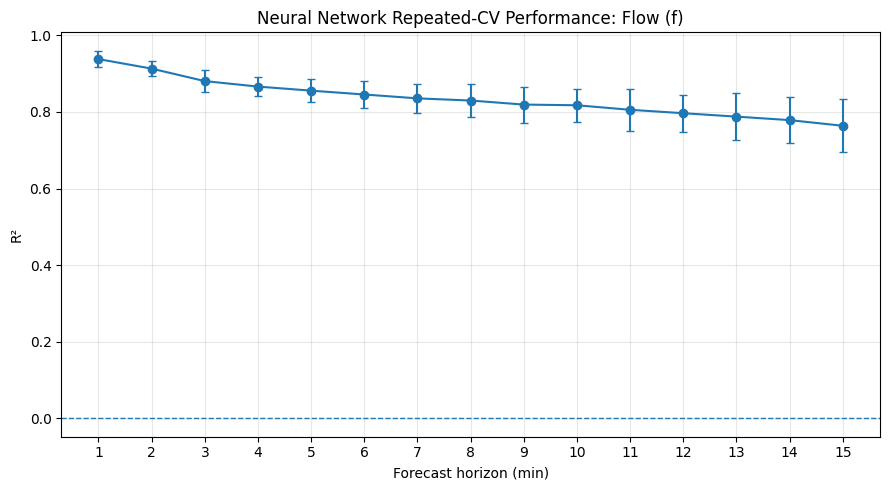

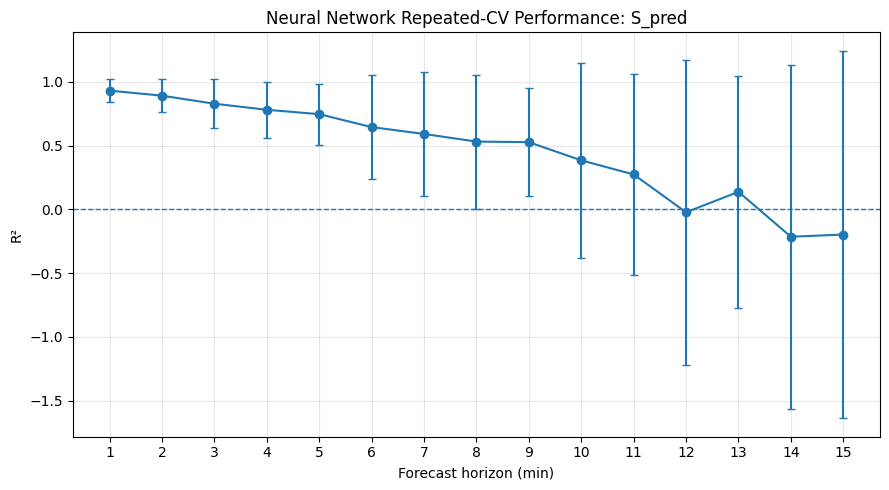

In [ ]:
# =============================================================================
# NN REPEATED-CV PERFORMANCE PLOTS
# =============================================================================

import matplotlib.pyplot as plt

for target in ['f', 'S_pred']:
    subset = (
        nn_summary_df[nn_summary_df['Target'] == target]
        .sort_values('Horizon (min)')
    )

    plt.figure(figsize=(9, 5))

    plt.errorbar(
        subset['Horizon (min)'],
        subset['Mean_R2'],
        yerr=subset['Std_R2'],
        marker='o',
        capsize=3
    )

    plt.axhline(0, linestyle='--', linewidth=1)

    plt.xticks(range(1, 16))
    plt.xlabel('Forecast horizon (min)')
    plt.ylabel('R²')

    target_name = 'Flow (f)' if target == 'f' else 'S_pred'
    plt.title(
        f'Neural Network Repeated-CV Performance: {target_name}'
    )

    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()

In [ ]:
# =============================================================================
# FINAL NEURAL NETWORK TRAINING
# 15 flow models + 15 S_pred models = 30 final models
# Cmax v8.2 / Portal 7-8 / exact same 18 Part-2 features
# =============================================================================

import os
import random
import joblib
import numpy as np
import pandas as pd
import tensorflow as tf

from sklearn.preprocessing import StandardScaler


# -----------------------------------------------------------------------------
# 1. CONFIG
# -----------------------------------------------------------------------------

FINAL_NN_DIR = os.path.join(
    NN_EXPORT_DIR,
    "final_models"
)
os.makedirs(FINAL_NN_DIR, exist_ok=True)

FINAL_RANDOM_STATE = 42

NN_MAX_EPOCHS = 150
NN_PATIENCE = 12
NN_BATCH_SIZE = 64
NN_LEARNING_RATE = 0.001

INTERNAL_VAL_FRACTION = 0.15

AM_WINDOW_START = pd.Timestamp("1900-01-01 07:30").time()
AM_WINDOW_END   = pd.Timestamp("1900-01-01 08:30").time()

FORECAST_STEPS = 15
TARGET_PORTAL_SEQ = 8


# exact same 18 Part-2 features
FINAL_FEATURE_COLS = [
    'p7_v',
    'p7_f',
    'p7_S_pred',

    'p7_v_lag1',
    'p7_v_lag2',

    'p7_f_lag1',
    'p7_f_lag2',

    'p7_S_pred_lag1',
    'p7_S_pred_lag2',

    'p8_v',
    'p8_f',
    'p8_S_pred',

    'p8_v_lag1',
    'p8_v_lag2',

    'p8_f_lag1',
    'p8_f_lag2',

    'p8_S_pred_lag1',
    'p8_S_pred_lag2'
]


FINAL_TARGET_CONFIG = {
    'f': {
        'smooth_window': 5,
        'predict_delta': False,
        'documented_reliable_through_min': 15
    },

    'S_pred': {
        'smooth_window': 5,
        'predict_delta': True,
        'documented_reliable_through_min': 8
    }
}


# -----------------------------------------------------------------------------
# 2. REPRODUCIBILITY
# -----------------------------------------------------------------------------

def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    tf.random.set_seed(seed)


# -----------------------------------------------------------------------------
# 3. SAME NN ARCHITECTURE USED IN CV
# -----------------------------------------------------------------------------

def build_final_mlp(input_dim, seed=42):

    set_seed(seed)

    model = tf.keras.Sequential([
        tf.keras.layers.Input(shape=(input_dim,)),

        tf.keras.layers.Dense(
            64,
            activation='relu'
        ),

        tf.keras.layers.Dropout(0.15),

        tf.keras.layers.Dense(
            32,
            activation='relu'
        ),

        tf.keras.layers.Dropout(0.15),

        tf.keras.layers.Dense(
            1,
            activation='linear'
        )
    ])

    model.compile(
        optimizer=tf.keras.optimizers.Adam(
            learning_rate=NN_LEARNING_RATE
        ),
        loss='mse'
    )

    return model


# -----------------------------------------------------------------------------
# 4. BUILD FINAL TRAINING SAMPLES
# -----------------------------------------------------------------------------

def build_final_nn_samples(corridor, target):

    cfg = FINAL_TARGET_CONFIG[target]

    df = corridor.copy()
    df['DateTime'] = pd.to_datetime(df['DateTime'])

    raw_target_col = f'p{TARGET_PORTAL_SEQ}_{target}'

    smooth_col = (
        f'{raw_target_col}_smoothed_w'
        f'{cfg["smooth_window"]}'
    )

    # same centred 5-minute smoothing
    df[smooth_col] = (
        df
        .groupby('Date')[raw_target_col]
        .transform(
            lambda s:
            s.rolling(
                window=cfg['smooth_window'],
                center=True,
                min_periods=1
            ).mean()
        )
    )

    X_rows = []
    Y_rows = []
    date_rows = []

    for i in range(len(df) - FORECAST_STEPS):

        origin_time = df.loc[i, 'DateTime']

        # only 07:30-08:30 forecast origins
        if not (
            AM_WINDOW_START
            <= origin_time.time()
            <= AM_WINDOW_END
        ):
            continue

        # full +15 horizon must stay in same calendar day
        if (
            df.loc[i, 'Date']
            !=
            df.loc[i + FORECAST_STEPS, 'Date']
        ):
            continue

        x = (
            df.loc[i, FINAL_FEATURE_COLS]
            .to_numpy(dtype=float)
        )

        if not np.all(np.isfinite(x)):
            continue

        current_raw = float(
            df.loc[i, raw_target_col]
        )

        future_values = []

        valid = True

        for h in range(1, FORECAST_STEPS + 1):

            value = float(
                df.loc[i + h, smooth_col]
            )

            if not np.isfinite(value):
                valid = False
                break

            # S_pred predicts delta from current raw value
            if cfg['predict_delta']:
                value = value - current_raw

            future_values.append(value)

        if not valid:
            continue

        X_rows.append(x)
        Y_rows.append(future_values)
        date_rows.append(df.loc[i, 'Date'])

    X = np.asarray(X_rows, dtype=float)
    Y = np.asarray(Y_rows, dtype=float)
    dates = np.asarray(date_rows)

    print("\n" + "=" * 80)
    print(f"FINAL TRAINING DATA: {target}")
    print("=" * 80)

    print("X shape:", X.shape)
    print("Y shape:", Y.shape)
    print("Unique days:", len(np.unique(dates)))
    print("predict_delta:", cfg['predict_delta'])
    print("smooth_window:", cfg['smooth_window'])

    return X, Y, dates


# -----------------------------------------------------------------------------
# 5. FINAL TRAINING FUNCTION
#
# Step A:
#   internal day-level validation only to determine best epoch
#
# Step B:
#   refit scaler on ALL 2021 samples
#   retrain fresh NN on ALL 2021 samples for that number of epochs
#
# This way the exported final model uses the full training dataset.
# -----------------------------------------------------------------------------

def train_one_final_horizon(
    X,
    y,
    dates,
    target,
    horizon
):

    unique_days = np.array(
        sorted(np.unique(dates))
    )

    rng = np.random.RandomState(
        FINAL_RANDOM_STATE + horizon
    )

    shuffled_days = unique_days.copy()
    rng.shuffle(shuffled_days)

    n_val_days = max(
        1,
        int(
            round(
                len(shuffled_days)
                * INTERNAL_VAL_FRACTION
            )
        )
    )

    val_days = set(
        shuffled_days[:n_val_days]
    )

    val_mask = np.array([
        d in val_days
        for d in dates
    ])

    fit_mask = ~val_mask


    # ------------------------------------------------------------------
    # Stage A: determine best epoch without touching final full-data fit
    # ------------------------------------------------------------------

    selection_scaler = StandardScaler()

    X_fit = selection_scaler.fit_transform(
        X[fit_mask]
    )

    X_val = selection_scaler.transform(
        X[val_mask]
    )

    y_fit = y[fit_mask]
    y_val = y[val_mask]

    selection_model = build_final_mlp(
        input_dim=X.shape[1],
        seed=FINAL_RANDOM_STATE + horizon
    )

    early_stop = tf.keras.callbacks.EarlyStopping(
        monitor='val_loss',
        patience=NN_PATIENCE,
        restore_best_weights=True,
        verbose=0
    )

    history = selection_model.fit(
        X_fit,
        y_fit,

        validation_data=(
            X_val,
            y_val
        ),

        epochs=NN_MAX_EPOCHS,
        batch_size=NN_BATCH_SIZE,

        callbacks=[
            early_stop
        ],

        verbose=0
    )

    best_epoch = (
        int(
            np.argmin(
                history.history['val_loss']
            )
        )
        + 1
    )


    # ------------------------------------------------------------------
    # Stage B: final model using ALL available 2021 samples
    # ------------------------------------------------------------------

    final_scaler = StandardScaler()

    X_all_scaled = final_scaler.fit_transform(
        X
    )

    final_model = build_final_mlp(
        input_dim=X.shape[1],
        seed=FINAL_RANDOM_STATE + horizon
    )

    final_model.fit(
        X_all_scaled,
        y,

        epochs=best_epoch,
        batch_size=NN_BATCH_SIZE,

        verbose=0
    )

    print(
        f"  Horizon +{horizon:02d} min"
        f" | selected epochs={best_epoch}"
        f" | fit samples={len(X):,}"
    )

    return (
        final_model,
        final_scaler,
        best_epoch
    )


# -----------------------------------------------------------------------------
# 6. TRAIN ALL 30 FINAL MODELS
# -----------------------------------------------------------------------------

final_nn_models = {}
final_nn_metadata = {}

for target in ['f', 'S_pred']:

    print("\n" + "#" * 100)
    print(
        f"FINAL NN TRAINING -- TARGET = {target}"
    )
    print("#" * 100)

    X, Y, sample_dates = (
        build_final_nn_samples(
            corridor_df,
            target
        )
    )

    target_models = []
    target_model_paths = []
    target_best_epochs = []

    # scaler is technically fitted separately for each horizon
    # because the final training function returns the corresponding
    # all-data scaler for that horizon.
    target_scalers = []

    for h in range(
        1,
        FORECAST_STEPS + 1
    ):

        y_h = Y[:, h - 1]

        model, scaler, best_epoch = (
            train_one_final_horizon(
                X=X,
                y=y_h,
                dates=sample_dates,
                target=target,
                horizon=h
            )
        )

        model_filename = (
            f"nn_{target}_h{h:02d}.keras"
        )

        model_path = os.path.join(
            FINAL_NN_DIR,
            model_filename
        )

        model.save(model_path)

        target_models.append(model)
        target_scalers.append(scaler)
        target_best_epochs.append(
            best_epoch
        )
        target_model_paths.append(
            model_path
        )


    final_nn_models[target] = {
        'models': target_models,
        'scalers': target_scalers,

        'feature_cols': (
            FINAL_FEATURE_COLS.copy()
        ),

        'smooth_window': (
            FINAL_TARGET_CONFIG[target]
            ['smooth_window']
        ),

        'predict_delta': (
            FINAL_TARGET_CONFIG[target]
            ['predict_delta']
        ),

        'documented_reliable_through_min': (
            FINAL_TARGET_CONFIG[target]
            ['documented_reliable_through_min']
        )
    }


    final_nn_metadata[target] = {
        'model_paths': (
            target_model_paths
        ),

        'best_epochs': (
            target_best_epochs
        ),

        'scalers': (
            target_scalers
        ),

        'feature_cols': (
            FINAL_FEATURE_COLS.copy()
        ),

        'smooth_window': (
            FINAL_TARGET_CONFIG[target]
            ['smooth_window']
        ),

        'predict_delta': (
            FINAL_TARGET_CONFIG[target]
            ['predict_delta']
        ),

        'documented_reliable_through_min': (
            FINAL_TARGET_CONFIG[target]
            ['documented_reliable_through_min']
        )
    }


# -----------------------------------------------------------------------------
# 7. SAVE METADATA / SCALERS
# -----------------------------------------------------------------------------

metadata_path = os.path.join(
    FINAL_NN_DIR,
    "nn_final_metadata.joblib"
)

export_artifact = {
    'model_type': 'Neural Network',

    'forecast_steps': FORECAST_STEPS,

    'interval_minutes': 1,

    'target_portal_seq': 8,

    'active_portals': [7, 8],

    'active_forecast_targets': [
        'f',
        'S_pred'
    ],

    'feature_cols': (
        FINAL_FEATURE_COLS.copy()
    ),

    'targets': (
        final_nn_metadata
    )
}

joblib.dump(
    export_artifact,
    metadata_path
)


print("\n" + "=" * 100)
print("FINAL NN TRAINING COMPLETE")
print("=" * 100)

print(
    "Models saved in:",
    FINAL_NN_DIR
)

print(
    "Metadata saved:",
    metadata_path
)

print(
    "\nNumber of final models:",
    sum(
        len(
            final_nn_models[t]['models']
        )
        for t in final_nn_models
    )
)


####################################################################################################
FINAL NN TRAINING -- TARGET = f
####################################################################################################

FINAL TRAINING DATA: f
X shape: (13054, 18)
Y shape: (13054, 15)
Unique days: 214
predict_delta: False
smooth_window: 5
  Horizon +01 min | selected epochs=36 | fit samples=13,054
  Horizon +02 min | selected epochs=45 | fit samples=13,054
  Horizon +03 min | selected epochs=37 | fit samples=13,054
  Horizon +04 min | selected epochs=48 | fit samples=13,054
  Horizon +05 min | selected epochs=46 | fit samples=13,054
  Horizon +06 min | selected epochs=62 | fit samples=13,054
  Horizon +07 min | selected epochs=37 | fit samples=13,054
  Horizon +08 min | selected epochs=47 | fit samples=13,054
  Horizon +09 min | selected epochs=58 | fit samples=13,054
  Horizon +10 min | selected epochs=16 | fit samples=13,054
  Horizon +11 min | selected epochs=38 | fit

In [ ]:
# =============================================================================
# ALIGN SAVED NN STRUCTURE WITH TEAMMATE'S XGBOOST FORMAT
# NO RETRAINING
# =============================================================================

import os
import joblib

# 1. Align in-memory structure
horizon_models = {}

for target in ['f', 'S_pred']:
    old_entry = final_nn_models[target]

    horizon_models[target] = {
        'models': old_entry['models'],
        'scaler': old_entry['scalers'][0],   # all scalers confirmed identical
        'feature_cols': old_entry['feature_cols'],
        'smooth_window': old_entry['smooth_window'],
        'predict_delta': old_entry['predict_delta'],
        'documented_reliable_through_min':
            old_entry['documented_reliable_through_min']
    }


# 2. Also clean the saved metadata so future loading uses the same structure
metadata_path = os.path.join(
    FINAL_NN_DIR,
    'nn_final_metadata.joblib'
)

artifact = joblib.load(metadata_path)

for target in ['f', 'S_pred']:
    target_entry = artifact['targets'][target]

    # keep only ONE scaler, matching teammate's structure
    if 'scalers' in target_entry:
        target_entry['scaler'] = target_entry['scalers'][0]
        del target_entry['scalers']

joblib.dump(artifact, metadata_path)


# 3. Check
print("NN structure aligned with XGBoost format.")

for target in ['f', 'S_pred']:
    entry = horizon_models[target]

    print(
        target,
        "| models =", len(entry['models']),
        "| features =", len(entry['feature_cols']),
        "| smooth_window =", entry['smooth_window'],
        "| predict_delta =", entry['predict_delta']
    )

print("Updated metadata:", metadata_path)

NN structure aligned with XGBoost format.
f | models = 15 | features = 18 | smooth_window = 5 | predict_delta = False
S_pred | models = 15 | features = 18 | smooth_window = 5 | predict_delta = True
Updated metadata: /content/drive/MyDrive/AH2179 GP5/prediction model NN (Cmax v8.2, portals 7-8)/final_models/nn_final_metadata.joblib


In [ ]:
# =============================================================================
# INTERACTIVE PART 2 PREDICTION VIEWER -- NEURAL NETWORK
# Same structure as teammate's FINAL C_max v8.2-compatible viewer
# =============================================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import ipywidgets as widgets

from IPython.display import display


# =============================================================================
# CONFIGURATION
# =============================================================================

AM_WINDOW_START = pd.Timestamp('1900-01-01 07:30').time()
AM_WINDOW_END = pd.Timestamp('1900-01-01 08:30').time()

CONTEXT_BEFORE_MINUTES = 10

TARGET_LABELS = {
    'f': 'f (flow)',
    'S_pred': 'S_pred (capacity-normalised congestion)',
}


# =============================================================================
# FIND MODEL AND FEATURE FRAME
# =============================================================================

def load_models():

    if 'horizon_models' not in globals():
        raise RuntimeError(
            'horizon_models not found. '
            'Run the NN structure-alignment cell first.'
        )

    print('[Viewer] Using in-memory NN horizon_models.')

    return globals()['horizon_models'], {
        'forecast_steps': globals().get('FORECAST_STEPS', 15),
        'target_portal_seq': globals().get('TARGET_PORTAL_SEQ', 8),
        'active_forecast_targets': ['f', 'S_pred'],
    }


def load_feature_frame():

    if 'eval_corridor_df' in globals():
        print(
            '[Viewer] Using eval_corridor_df '
            '(recommended: evaluation/holdout feature frame).'
        )
        return globals()['eval_corridor_df'].copy(), 'evaluation data'

    if 'corridor_df' in globals():
        print(
            '[Viewer warning] Using corridor_df from model training. '
            'This is useful for visual inspection but not external validation.'
        )
        return globals()['corridor_df'].copy(), 'training data'

    raise RuntimeError(
        'No feature frame found. '
        'Need eval_corridor_df or corridor_df.'
    )


horizon_models, model_metadata = load_models()

viewer_df, viewer_data_source = load_feature_frame()


FORECAST_STEPS = int(
    model_metadata.get(
        'forecast_steps',
        15
    )
)

TARGET_PORTAL_SEQ = int(
    model_metadata.get(
        'target_portal_seq',
        8
    )
)

AVAILABLE_TARGETS = [
    target
    for target in model_metadata.get(
        'active_forecast_targets',
        horizon_models.keys()
    )
    if target in horizon_models
]


viewer_df['DateTime'] = pd.to_datetime(
    viewer_df['DateTime']
)

viewer_df = (
    viewer_df
    .sort_values('DateTime')
    .reset_index(drop=True)
)

viewer_df['_Time'] = (
    viewer_df['DateTime']
    .dt.time
)

viewer_df['_DateString'] = (
    viewer_df['DateTime']
    .dt.strftime('%Y-%m-%d')
)


am_mask = (
    (viewer_df['_Time'] >= AM_WINDOW_START)
    &
    (viewer_df['_Time'] <= AM_WINDOW_END)
)

available_dates = sorted(
    viewer_df.loc[
        am_mask,
        '_DateString'
    ].unique()
)

if not available_dates:
    raise ValueError(
        'No 07:30-08:30 AM-window instances '
        'exist in the available feature frame.'
    )

print(
    f'[Viewer] Ready: '
    f'{len(available_dates)} selectable dates; '
    f'targets={AVAILABLE_TARGETS}; '
    f'source={viewer_data_source}.'
)


# =============================================================================
# DATA / PREDICTION HELPERS
# =============================================================================

def smoothed_actual_column(
    target_name,
    entry
):

    raw_column = (
        f'p{TARGET_PORTAL_SEQ}_{target_name}'
    )

    window = int(
        entry.get(
            'smooth_window',
            1
        )
    )

    column_name = (
        f'_viewer_{raw_column}'
        f'_smoothed_w{window}'
    )

    if column_name not in viewer_df.columns:

        if window <= 1:

            viewer_df[column_name] = (
                viewer_df[raw_column]
            )

        else:

            viewer_df[column_name] = (
                viewer_df
                .groupby('Date')[raw_column]
                .transform(
                    lambda values:
                    values.rolling(
                        window=window,
                        center=True,
                        min_periods=1
                    ).mean()
                )
            )

    return raw_column, column_name


def valid_instances_for_date(
    date_string
):

    subset = viewer_df[
        (viewer_df['_DateString'] == date_string)
        &
        am_mask
    ].copy()

    valid_times = []

    for index in subset.index:

        end_index = (
            index
            + FORECAST_STEPS
        )

        if end_index >= len(viewer_df):
            continue

        if (
            viewer_df.loc[
                index,
                'Date'
            ]
            !=
            viewer_df.loc[
                end_index,
                'Date'
            ]
        ):
            continue

        valid_times.append(
            viewer_df.loc[
                index,
                'DateTime'
            ].strftime('%H:%M')
        )

    return valid_times


def locate_instance(
    date_string,
    time_string
):

    matches = viewer_df[
        (
            viewer_df['_DateString']
            == date_string
        )
        &
        (
            viewer_df['DateTime']
            .dt.strftime('%H:%M')
            == time_string
        )
    ]

    if matches.empty:
        raise ValueError(
            f'No row found for '
            f'date={date_string}, '
            f'time={time_string}.'
        )

    return int(
        matches.index[0]
    )


def predict_all_horizons(
    row_index,
    target_name
):

    entry = (
        horizon_models[
            target_name
        ]
    )

    features = (
        entry['feature_cols']
    )

    x = viewer_df.loc[
        [row_index],
        features
    ].to_numpy(dtype=float)


    # Same structure as teammate:
    # one scaler per target
    scaled_x = (
        entry['scaler']
        .transform(x)
    )


    # Only necessary difference:
    # Keras NN uses predict(..., verbose=0)
    predictions = np.asarray([
        float(
            entry['models'][step]
            .predict(
                scaled_x,
                verbose=0
            )
            .ravel()[0]
        )
        for step in range(
            FORECAST_STEPS
        )
    ])


    raw_column = (
        f'p{TARGET_PORTAL_SEQ}_'
        f'{target_name}'
    )

    current_value = float(
        viewer_df.loc[
            row_index,
            raw_column
        ]
    )


    if entry.get(
        'predict_delta',
        False
    ):
        predictions = (
            predictions
            + current_value
        )


    return (
        predictions,
        current_value
    )


# =============================================================================
# PLOT FUNCTION
# =============================================================================

def plot_prediction_instance(
    selected_date,
    selected_time,
    target_name
):

    if target_name not in AVAILABLE_TARGETS:

        raise ValueError(
            f'Unknown target '
            f'{target_name}; '
            f'choices: {AVAILABLE_TARGETS}'
        )


    row_index = locate_instance(
        selected_date,
        selected_time
    )


    if (
        row_index
        + FORECAST_STEPS
        >= len(viewer_df)
    ):
        raise ValueError(
            'Selected instance does not have '
            'a complete 15-minute future horizon.'
        )


    if (
        viewer_df.loc[
            row_index,
            'Date'
        ]
        !=
        viewer_df.loc[
            row_index
            + FORECAST_STEPS,
            'Date'
        ]
    ):
        raise ValueError(
            'Selected instance crosses '
            'a calendar-day boundary '
            'before +15 minutes.'
        )


    entry = (
        horizon_models[
            target_name
        ]
    )


    raw_column, smooth_column = (
        smoothed_actual_column(
            target_name,
            entry
        )
    )


    predictions, current_value = (
        predict_all_horizons(
            row_index,
            target_name
        )
    )


    start_index = max(
        0,
        row_index
        - CONTEXT_BEFORE_MINUTES
    )

    end_index = min(
        len(viewer_df) - 1,
        row_index
        + FORECAST_STEPS
    )


    view = viewer_df.loc[
        start_index:end_index,
        [
            'DateTime',
            raw_column,
            smooth_column
        ]
    ].copy()


    view['minutes_relative'] = (
        (
            view['DateTime']
            -
            viewer_df.loc[
                row_index,
                'DateTime'
            ]
        )
        .dt.total_seconds()
        / 60.0
    )


    horizons = np.arange(
        1,
        FORECAST_STEPS + 1
    )


    future_rows = viewer_df.loc[
        row_index + 1:
        row_index + FORECAST_STEPS
    ]


    actual_raw = (
        future_rows[
            raw_column
        ]
        .to_numpy(dtype=float)
    )


    actual_smooth = (
        future_rows[
            smooth_column
        ]
        .to_numpy(dtype=float)
    )


    errors = (
        predictions
        -
        actual_smooth
    )


    origin_time = (
        viewer_df.loc[
            row_index,
            'DateTime'
        ]
    )


    reliable_until = (
        entry.get(
            'documented_reliable_through_min',
            FORECAST_STEPS
        )
    )


    target_label = (
        TARGET_LABELS.get(
            target_name,
            target_name
        )
    )


    # =========================================================================
    # PLOT
    # =========================================================================

    fig, ax = plt.subplots(
        figsize=(12, 6.5)
    )


    # Grey dotted raw observed
    ax.plot(
        view['minutes_relative'],
        view[raw_column],

        color='#9E9E9E',
        linestyle=':',
        linewidth=1.7,

        marker='o',
        markersize=3,

        label='Raw observed value'
    )


    # Black line = smoothed actual
    ax.plot(
        view['minutes_relative'],
        view[smooth_column],

        color='black',
        linewidth=2.2,

        marker='o',
        markersize=3.5,

        label=(
            'Actual model target '
            f'(smoothed, w='
            f'{entry.get("smooth_window", 1)})'
        )
    )


    # Red dashed = NN prediction
    ax.plot(
        horizons,
        predictions,

        color='#D62728',
        linestyle='--',
        linewidth=2.0,

        marker='o',
        markersize=5,

        label=(
            'Predicted level '
            '(+1 to +15 min)'
        )
    )


    # Forecast origin t=0
    ax.axvline(
        0,

        color='#444444',
        linestyle=':',
        linewidth=1.5,

        label='Forecast origin (t=0)'
    )


    # Shaded informational range
    if reliable_until < FORECAST_STEPS:

        ax.axvspan(
            reliable_until + 0.5,
            FORECAST_STEPS + 0.5,

            color='#F4A261',
            alpha=0.12,

            label=(
                'Informational range '
                f'after +{reliable_until} min'
            )
        )


    ax.set_title(
        f'Portal {TARGET_PORTAL_SEQ}: '
        f'{target_label}\n'
        f'Forecast origin: '
        f'{origin_time:%Y-%m-%d %H:%M} | '
        f'source: {viewer_data_source}'
    )


    ax.set_xlabel(
        'Minutes relative to selected '
        'forecast origin'
    )


    ax.set_ylabel(
        target_label
    )


    ax.grid(
        alpha=0.25
    )


    ax.legend(
        loc='best'
    )


    fig.tight_layout()

    plt.show()


    # =========================================================================
    # COMPARISON TABLE
    # =========================================================================

    comparison = pd.DataFrame({

        'Horizon_min':
            horizons,

        'Predicted_Level':
            predictions,

        'Actual_Smoothed_Level':
            actual_smooth,

        'Actual_Raw_Level':
            actual_raw,

        'Residual_Pred_minus_Smoothed_Actual':
            errors,

        'Absolute_Error_vs_Smoothed_Actual':
            np.abs(errors),

        'Within_Documented_Deployment_Range':
            horizons <= reliable_until
    })


    print(
        '\nSelected origin details'
    )

    print(
        f'  Date/time: '
        f'{origin_time}'
    )

    print(
        f'  Target: '
        f'{target_name}'
    )

    print(
        f'  Current raw value at t=0: '
        f'{current_value:.6f}'
    )

    print(
        f'  Smoothing window: '
        f'{entry.get("smooth_window", 1)} '
        f'minute(s)'
    )

    print(
        f'  Delta prediction: '
        f'{entry.get("predict_delta", False)}'
    )

    print(
        '  Documented deployment range: '
        f'+1 to +{reliable_until} '
        'minute(s)'
    )

    print(
        '\nHorizon comparison:'
    )

    print(
        comparison
        .round(5)
        .to_string(index=False)
    )


    return comparison


# =============================================================================
# INTERACTIVE WIDGET
# =============================================================================

def show_prediction_viewer():

    date_dropdown = widgets.Dropdown(

        options=available_dates,

        value=available_dates[0],

        description='Date:',

        layout=widgets.Layout(
            width='350px'
        )
    )


    initial_times = (
        valid_instances_for_date(
            available_dates[0]
        )
    )


    if not initial_times:

        raise ValueError(
            f'No usable full-horizon '
            f'instances on '
            f'{available_dates[0]}.'
        )


    time_dropdown = widgets.Dropdown(

        options=initial_times,

        value=initial_times[0],

        description='Instance:',

        layout=widgets.Layout(
            width='350px'
        )
    )


    target_dropdown = widgets.Dropdown(

        options=AVAILABLE_TARGETS,

        value=AVAILABLE_TARGETS[0],

        description='Target:',

        layout=widgets.Layout(
            width='350px'
        )
    )


    def update_time_options(
        change
    ):

        times = (
            valid_instances_for_date(
                change['new']
            )
        )

        time_dropdown.options = (
            times
        )

        if times:

            time_dropdown.value = (
                times[0]
            )


    date_dropdown.observe(
        update_time_options,
        names='value'
    )


    output = widgets.interactive_output(

        plot_prediction_instance,

        {
            'selected_date':
                date_dropdown,

            'selected_time':
                time_dropdown,

            'target_name':
                target_dropdown
        }
    )


    selector_box = widgets.VBox([

        widgets.HTML(
            '<b>Part 2 Final Viewer</b><br>'
            'Grey = raw observed value; '
            'black = smoothed actual target; '
            'red = forecast. '
            'The shaded right-side region is '
            'beyond the target\'s documented '
            'deployment horizon.'
        ),

        date_dropdown,

        time_dropdown,

        target_dropdown
    ])


    display(
        selector_box,
        output
    )


# =============================================================================
# RUN VIEWER
# =============================================================================

print(
    '\n[Viewer] Initialisation complete.'
)

print(
    '[Viewer] Run: show_prediction_viewer()'
)

show_prediction_viewer()

[Viewer] Using in-memory NN horizon_models.
[Viewer warning] Using corridor_df from model training. This is useful for visual inspection but not external validation.
[Viewer] Ready: 214 selectable dates; targets=['f', 'S_pred']; source=training data.

[Viewer] Initialisation complete.
[Viewer] Run: show_prediction_viewer()


Output()